# Growing Economies, Falling Emissions? — Energy Transition Explorer
**CMSE 830 Midterm Project · Fall 2026 · Mehady Hassan**

**Question.** Which countries grew their economy (GDP) while clearly cutting their territorial CO₂ emissions
(*absolute decoupling*), and what changed in their electricity mix at the same time?

**Audience.** Students, journalists and interested citizens who hear the claim "you can't grow the economy and cut
emissions" and want to check it country by country. No statistics background is assumed; the Streamlit app
(`app.py`) is the interactive version of this notebook.

**How to run.** This notebook is **self-contained**: every setting and data-preparation function is defined inside it
(Section 0), and it does not import any project module or script. It only needs the standard packages pandas, numpy,
matplotlib, seaborn and scipy (`pip install -r requirements-dev.txt` installs them plus Jupyter). Open it and
*Run All*, or run `jupyter nbconvert --to notebook --execute --inplace energy_transition_analysis.ipynb`.

It looks for the three CSV files in a `data/` folder of the project (one level up when the notebook sits in
`notebooks/`, as in the repository; otherwise next to the notebook). Any file that is missing is downloaded from
Our World in Data. Every figure is saved to `docs/figures/` and every headline number to `docs/results.json` in the
same project folder (created if needed). The Streamlit app (`app.py`) contains the same preparation functions, so
the numbers here and in the app are identical.

**Contents**
0. [Settings and data-preparation functions](#0.-Settings-and-data-preparation-functions)
1. [Data collection](#1.-Data-collection)
2. [Initial data analysis (IDA)](#2.-Initial-data-analysis-(IDA))
3. [Feature engineering: the decoupling label](#3.-Feature-engineering:-the-decoupling-label)
4. [Exploratory data analysis, question by question](#4.-Exploratory-data-analysis,-question-by-question)
5. [Key results summary](#5.-Key-results-summary)
6. [Limitations](#6.-Limitations)

In [1]:
import json
from datetime import datetime
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Project folder: in the repository this notebook sits in notebooks/, so the project is one level up;
# anywhere else the notebook's own folder is used. data/ and docs/figures/ are created if they are missing.
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name == "notebooks" else HERE
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "docs" / "figures"
for folder in (DATA_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Plot style: readable fonts, light grid, Okabe-Ito colours (colour-blind safe), same as the app
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"font.family": "DejaVu Sans",  # has the subscript in "CO₂"
                     "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
                     "legend.fontsize": 9})
CLASS_COLORS = {"Absolute decoupling": "#009E73", "CO₂ about flat": "#E5C000", "Coupled growth": "#D55E00",
                "GDP fell": "#999999", "Insufficient data": "#DDDDDD"}
# Continents avoid the class colours, so a continent never reads as a decoupling group.
CONTINENT_COLORS = {"Africa": "#E69F00", "Asia": "#CC79A7", "Europe": "#0072B2",
                    "North America": "#56B4E9", "South America": "#B8A800", "Oceania": "#000000"}
SERIES_COLORS = {"GDP": "#0072B2", "CO₂ (territorial)": "#D55E00", "Population": "#999999"}
CO2_KIND_COLORS = {"Territorial CO₂": "#0072B2", "Consumption-based CO₂": "#E69F00"}
SOURCE_NOTE = "Source: Our World in Data (CO₂, energy, continents), CC BY 4.0."

R = {}  # every headline number goes in here and is written to docs/results.json at the end


PLAIN = plt.FuncFormatter(lambda v, _: f"{v:g}")   # 0.1, 1, 10 instead of 10^-1, 10^0, 10^1


def save(fig, name):
    fig.savefig(FIG_DIR / name)
    print("saved", (FIG_DIR / name).relative_to(ROOT))

## 0. Settings and data-preparation functions

Everything the analysis needs is defined here, so the notebook runs on its own. The Streamlit app (`app.py`)
contains the same functions, which is why the app and this notebook show the same numbers.

- **Years.** The panel keeps 1990–2023 so the data checks can look at every year, but comparisons start in
  **2000** (Section 2.5 shows why: electricity data are mostly missing in the 1990s, and the post-Soviet collapse
  would make some countries look like "decouplers").
- **Margin.** A CO₂ change of ±5% or less counts as "about flat" (Section 3 explains the choice).
- **`load_raw`** reads the three CSV files exactly as downloaded.
- **`build_panel`** drops region rows, joins the CO₂ and energy files on (ISO code, year), adds the continent and
  GDP per person, and reports what the join kept and lost.
- **`decoupling_table`** compares every country between two years and gives it one label.

In [2]:
YEAR_MIN, YEAR_MAX = 1990, 2023  # years kept in the panel (the data checks look at all of them)
ANALYSIS_START = 2000            # first year any comparison may use
FLAT_BAND_PCT = 5                # CO2 changes within +/- this many percent count as "about flat"

CO2_COLS = ["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita",
            "consumption_co2", "consumption_co2_per_capita", "primary_energy_consumption"]
ENERGY_COLS = ["iso_code", "year", "coal_share_elec", "oil_share_elec", "gas_share_elec",
               "nuclear_share_elec", "hydro_share_elec", "wind_share_elec", "solar_share_elec",
               "other_renewables_share_elec", "low_carbon_share_elec", "fossil_share_elec",
               "renewables_share_elec", "carbon_intensity_elec"]
CLASS_ORDER = ["Absolute decoupling", "CO₂ about flat", "Coupled growth", "GDP fell", "Insufficient data"]


def load_raw(data_dir=DATA_DIR):
    """Read the three raw CSV files exactly as downloaded."""
    co2 = pd.read_csv(data_dir / "owid-co2-data.csv")
    energy = pd.read_csv(data_dir / "owid-energy-data.csv")
    continents = pd.read_csv(data_dir / "owid-continents.csv")
    return co2, energy, continents


def build_panel(co2, energy, continents, year_min=YEAR_MIN, year_max=YEAR_MAX):
    """Return (panel, join_report).

    panel: one row per country-year, countries only, CO2 and energy data joined.
    join_report: counts of rows that matched / did not match in the join.
    """
    # 1. Aggregates ("World", "Africa", "High-income countries", ...) have no ISO code.
    c = co2[co2["iso_code"].notna() & co2["year"].between(year_min, year_max)][CO2_COLS]
    e = energy[energy["iso_code"].notna() & energy["year"].between(year_min, year_max)][ENERGY_COLS]

    # 2. Join on ISO code + year. Outer join first so unmatched rows can be reported.
    j = c.merge(e, on=["iso_code", "year"], how="outer", indicator=True)
    join_report = j["_merge"].map({"both": "matched", "left_only": "CO2 file only",
                                   "right_only": "energy file only"}).value_counts()
    # Keep every country-year that has CO2 data (energy columns may be NaN).
    panel = j[j["_merge"] != "right_only"].drop(columns="_merge").copy()

    # 3. Continent lookup (OWID's own classification).
    cont = continents.dropna(subset=["code"]).set_index("code")["owid_region"]
    panel["continent"] = panel["iso_code"].map(cont)

    # 4. Derived variable.
    panel["gdp_per_capita"] = panel["gdp"] / panel["population"]
    return panel.sort_values(["country", "year"]).reset_index(drop=True), join_report


def decoupling_table(panel, start, end, band=FLAT_BAND_PCT):
    """Compare each country between two years and label it.

    Absolute decoupling = GDP went up AND territorial CO2 fell by more than `band` %.
    CO2 about flat      = GDP went up and CO2 changed by `band` % or less (either way).
    Coupled growth      = GDP went up and CO2 rose by more than `band` %.
    Countries without GDP or CO2 in either year are labelled "Insufficient data"
    (GDP is NOT imputed - a verdict built on invented GDP would be misleading).
    """
    keep = ["gdp", "co2", "population", "low_carbon_share_elec", "coal_share_elec",
            "co2_per_capita", "consumption_co2"]
    a = panel[panel["year"] == start].set_index("iso_code")[keep]
    b = panel[panel["year"] == end].set_index("iso_code")[keep]
    info = panel.drop_duplicates("iso_code").set_index("iso_code")[["country", "continent"]]
    t = info.join(a.add_suffix("_start")).join(b.add_suffix("_end"))

    t["gdp_change_pct"] = (t["gdp_end"] / t["gdp_start"] - 1) * 100
    t["co2_change_pct"] = (t["co2_end"] / t["co2_start"] - 1) * 100
    t["cons_co2_change_pct"] = (t["consumption_co2_end"] / t["consumption_co2_start"] - 1) * 100
    t["low_carbon_change_pp"] = t["low_carbon_share_elec_end"] - t["low_carbon_share_elec_start"]
    t["coal_change_pp"] = t["coal_share_elec_end"] - t["coal_share_elec_start"]

    ok = t["gdp_change_pct"].notna() & t["co2_change_pct"].notna()
    grew = t["gdp_change_pct"] > 0
    t["decoupling"] = np.select(
        [~ok, ~grew, t["co2_change_pct"] < -band, t["co2_change_pct"] <= band],
        ["Insufficient data", "GDP fell", "Absolute decoupling", "CO₂ about flat"],
        default="Coupled growth")
    return t.reset_index()


## 1. Data collection

All data are public and come from **Our World in Data (OWID)**, licensed **CC BY 4.0** (free to reuse with credit):

| File | Content | Original sources |
|---|---|---|
| `owid-co2-data.csv` | territorial and consumption-based CO₂, GDP, population | Global Carbon Project, Maddison Project, UN |
| `owid-energy-data.csv` | electricity mix shares (coal, gas, nuclear, wind, solar, ...) | Energy Institute, Ember |
| `owid-continents.csv` | continent of each country | OWID |

**Unit of observation: one country in one year** (country × year panel). The continents file is a lookup table
(one row per country).

The cell below lists the three source URLs and downloads a file only if it is missing (or if
`FORCE_DOWNLOAD = True`). Each download goes to a temporary file first, so a broken connection never leaves a
half-written CSV behind, and an error is caught, so the notebook still runs offline with the saved snapshot.

In [3]:
FORCE_DOWNLOAD = False   # set True to refresh the snapshot (OWID updates the files, numbers may change slightly)
SNAPSHOT_DATE = "2026-10-16"   # date the CSVs in data/ were downloaded (shown when they are not re-downloaded)
URLS = {
    "owid-co2-data.csv": "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv",
    "owid-energy-data.csv": "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv",
    "owid-continents.csv": ("https://ourworldindata.org/grapher/continents-according-to-our-world-in-data.csv"
                            "?v=1&csvType=full&useColumnShortNames=true"),
}

downloaded = set()
for name, url in URLS.items():
    path = DATA_DIR / name
    if path.exists() and not FORCE_DOWNLOAD:
        continue
    try:
        print(f"Downloading {name} ...")
        part = path.with_name(name + ".part")
        urlretrieve(url, part)
        part.replace(path)
        downloaded.add(name)
    except Exception as err:  # offline or URL changed: keep going with whatever is on disk
        print(f"Could not download {name}: {err}")
missing = [name for name in URLS if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"{missing} not found in {DATA_DIR}. Connect to the internet and re-run, "
                            "or copy the CSV files into that folder.")

co2_raw, energy_raw, continents_raw = load_raw(DATA_DIR)
raw = {"owid-co2-data.csv": co2_raw, "owid-energy-data.csv": energy_raw, "owid-continents.csv": continents_raw}
files = pd.DataFrame([{
    "file": name,
    "size_MB": round((DATA_DIR / name).stat().st_size / 1e6, 2),
    "rows": df.shape[0], "columns": df.shape[1],
    "years": f"{df['year'].min()}–{df['year'].max()}",
    # file dates change on git clone, so use the recorded snapshot date unless the file was just downloaded
    "snapshot_date": (datetime.now().strftime("%Y-%m-%d") if name in downloaded
                      else SNAPSHOT_DATE),
} for name, df in raw.items()])
files

,file,size_MB,rows,columns,years,snapshot_date
0,owid-co2-data.csv,14.38,50411,79,1750–2024,2026-10-16
1,owid-energy-data.csv,9.23,23377,130,1900–2025,2026-10-16
2,owid-continents.csv,0.01,272,4,2023–2023,2026-10-16


In [4]:
R["data_files"] = {r["file"]: {"url": URLS[r["file"]], "size_mb": r["size_MB"], "rows": int(r["rows"]),
                               "columns": int(r["columns"]), "years": r["years"],
                               "snapshot_date": r["snapshot_date"]} for _, r in files.iterrows()}
R["licence"] = "CC BY 4.0 (Our World in Data)"
R["unit_of_observation"] = "country x year"
R["analysis_years"] = [YEAR_MIN, YEAR_MAX]
R["comparisons_from_year"] = ANALYSIS_START
R["flat_band_pct"] = FLAT_BAND_PCT
co2_raw[["country", "year", "iso_code", "population", "gdp", "co2", "co2_per_capita"]].tail(3)

,country,year,iso_code,population,gdp,co2,co2_per_capita
50408,Zimbabwe,2022,ZWE,16069061.0,2.590159e+10,12.232,0.761
50409,Zimbabwe,2023,ZWE,16340829.0,NaN,13.443,0.823
50410,Zimbabwe,2024,ZWE,16634366.0,NaN,13.701,0.824


## 2. Initial data analysis (IDA)

The rule I follow here is **assess first, then decide**: every check prints what it finds, and each repair is written
as a **Decision:** line with the reason. If a step is not needed (for example, there are no duplicates to remove),
I say so instead of forcing it.

### 2.1 Column selection and data types
The two big files have 79 and 130 columns. The question only needs a few of them, so `build_panel` (Section 0) keeps:

- **CO₂ file:** country, year, ISO code, population, GDP, territorial CO₂ (total and per capita),
  consumption-based CO₂ (total and per capita), primary energy.
- **Energy file:** electricity shares of each source (coal, oil, gas, nuclear, hydro, wind, solar, other
  renewables), plus the summary shares *low-carbon*, *fossil*, *renewables*, and carbon intensity of electricity.

Units: CO₂ in million tonnes (Mt), CO₂ per capita in tonnes, GDP in international dollars (2011 prices, PPP),
electricity shares in % of generation.

In [5]:
panel, join_report = build_panel(co2_raw, energy_raw, continents_raw)
print(f"Cleaned panel: {panel.shape[0]:,} country-years x {panel.shape[1]} columns, "
      f"{panel['iso_code'].nunique()} countries, {YEAR_MIN}–{YEAR_MAX}")
dtypes = panel.dtypes.astype(str).value_counts()
print("dtypes:", dtypes.to_dict())
panel[["country", "year", "iso_code", "continent", "gdp", "co2", "co2_per_capita",
       "low_carbon_share_elec", "coal_share_elec"]].head()

Cleaned panel: 7,412 country-years x 24 columns, 218 countries, 1990–2023
dtypes: {'float64': 20, 'object': 3, 'int64': 1}


,country,year,iso_code,continent,gdp,co2,co2_per_capita,low_carbon_share_elec,coal_share_elec
0,Afghanistan,1990,AFG,Asia,1.306598e+10,2.024,0.168,NaN,NaN
1,Afghanistan,1991,AFG,Asia,1.204736e+10,1.914,0.156,NaN,NaN
2,Afghanistan,1992,AFG,Asia,1.267754e+10,1.482,0.112,NaN,NaN
3,Afghanistan,1993,AFG,Asia,9.834582e+09,1.487,0.100,NaN,NaN
4,Afghanistan,1994,AFG,Asia,7.919856e+09,1.454,0.089,NaN,NaN


**Assessment.** Identifiers (`country`, `iso_code`, `continent`) are text, `year` is an integer and every measurement
is a float, so no type conversion is needed. **Decision:** keep the dtypes as read (N/A — no repair needed).

### 2.2 Aggregate rows (regions and groups)
Rows such as "World" or "Europe" are sums of countries. Mixing them with countries would double-count emissions.
In OWID these rows have no ISO code.

In [6]:
agg = co2_raw[co2_raw["iso_code"].isna()]
agg_names = sorted(agg["country"].unique())
print(f"CO₂ file: {len(agg):,} rows without ISO code from {len(agg_names)} entities")
print("Examples:", agg_names[:6], "...", agg_names[-6:])
agg_energy = energy_raw[energy_raw["iso_code"].isna()]
print(f"Energy file: {len(agg_energy):,} rows without ISO code from {agg_energy['country'].nunique()} entities")
print("Kosovo is the one real country in this group (it has no official ISO-3 code):",
      "Kosovo" in agg_names)

R["aggregates"] = {"co2_rows_without_iso": int(len(agg)), "co2_entities_without_iso": len(agg_names),
                   "energy_rows_without_iso": int(len(agg_energy)),
                   "energy_entities_without_iso": int(agg_energy["country"].nunique()),
                   "examples": agg_names[:6], "kosovo_dropped": "Kosovo" in agg_names}

CO₂ file: 7,931 rows without ISO code from 36 entities
Examples: ['Africa', 'Africa (GCP)', 'Asia', 'Asia (GCP)', 'Asia (excl. China and India)', 'Central America (GCP)'] ... ['Ryukyu Islands', 'Ryukyu Islands (GCP)', 'South America', 'South America (GCP)', 'Upper-middle-income countries', 'World']
Energy file: 6,112 rows without ISO code from 94 entities
Kosovo is the one real country in this group (it has no official ISO-3 code): True


**Decision:** drop all rows without an ISO code (regions, income groups, "International shipping", etc.).
This also drops Kosovo, which has no ISO-3 code in OWID; it is one small country, so I document it rather than invent a
code for it.

### 2.3 Joining the two files on (iso_code, year)
I first do an **outer join** so I can see which rows would be lost, then keep every row that has CO₂ data
(electricity columns may be empty).

_merge
matched             6931
CO2 file only        481
energy file only     476

12 countries only in the CO₂ file: ['Anguilla', 'Andorra', 'Bonaire Sint Eustatius and Saba', 'Christmas Island', 'Liechtenstein', 'Monaco', 'Marshall Islands', 'Palau', 'San Marino', 'Sint Maarten (Dutch part)', 'Vatican', 'Wallis and Futuna']
14 countries only in the energy file: ['Netherlands Antilles', 'American Samoa', 'Cayman Islands', 'Western Sahara', 'Falkland Islands', 'Gibraltar', 'Guadeloupe', 'French Guiana', 'Guam', 'Northern Mariana Islands', 'Martinique', 'Puerto Rico', 'Reunion', 'United States Virgin Islands']


saved docs/figures/fig01_join_coverage.png


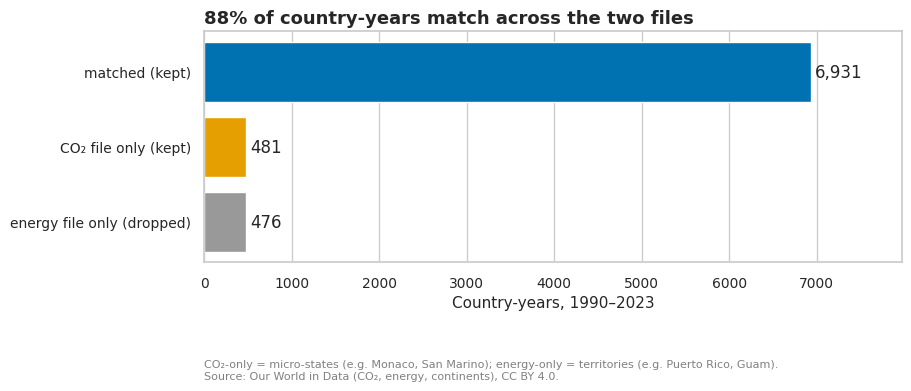

In [7]:
join = join_report.reindex(["matched", "CO2 file only", "energy file only"])
print(join.to_string())

c = co2_raw[co2_raw["iso_code"].notna() & co2_raw["year"].between(YEAR_MIN, YEAR_MAX)]
e = energy_raw[energy_raw["iso_code"].notna() & energy_raw["year"].between(YEAR_MIN, YEAR_MAX)]
co2_only = sorted(set(c["iso_code"]) - set(e["iso_code"]))
energy_only = sorted(set(e["iso_code"]) - set(c["iso_code"]))
name_of = pd.concat([c, e]).drop_duplicates("iso_code").set_index("iso_code")["country"]
print(f"\n{len(co2_only)} countries only in the CO₂ file:", [name_of[i] for i in co2_only])
print(f"{len(energy_only)} countries only in the energy file:", [name_of[i] for i in energy_only])

R["join"] = {"matched_rows": int(join["matched"]), "co2_only_rows": int(join["CO2 file only"]),
             "energy_only_rows": int(join["energy file only"]),
             "co2_only_countries": [name_of[i] for i in co2_only],
             "energy_only_countries": [name_of[i] for i in energy_only],
             "panel_rows": int(len(panel)), "panel_countries": int(panel["iso_code"].nunique())}

fig, ax = plt.subplots(figsize=(9, 3))
colors = ["#0072B2", "#E69F00", "#999999"]
bar_labels = ["matched (kept)", "CO₂ file only (kept)", "energy file only (dropped)"]
ax.barh(bar_labels[::-1], join.values[::-1], color=colors[::-1])
for i, v in enumerate(join.values[::-1]):
    ax.text(v + 50, i, f"{v:,}", va="center")
ax.set(xlabel="Country-years, 1990–2023", xlim=(0, join.max() * 1.15),
       title=f"{join['matched'] / join.sum():.0%} of country-years match across the two files")
ax.text(0, -0.42, "CO₂-only = micro-states (e.g. Monaco, San Marino); energy-only = territories (e.g. Puerto Rico, Guam).\n"
        + SOURCE_NOTE, transform=ax.transAxes, fontsize=8, color="grey", va="top")
ax.grid(axis="y", visible=False)
save(fig, "fig01_join_coverage.png"); plt.show()

**Decision:** keep the CO₂-only rows (micro-states still have CO₂ and sometimes GDP; their electricity columns are just
empty) and drop the energy-only rows (territories with no CO₂/GDP cannot answer the question). Nothing is dropped
silently: the counts above are also shown in the app's *Data & preparation* tab.

### 2.4 Duplicates and consistency checks

In [8]:
share_cols = [col for col in panel.columns if col.endswith("_share_elec")]
names = (co2_raw[["iso_code", "country"]].dropna().drop_duplicates()
         .merge(energy_raw[["iso_code", "country"]].dropna().drop_duplicates(),
                on="iso_code", suffixes=("_co2", "_energy")))
checks = pd.Series({
    "duplicate (iso_code, year) in CO₂ file": int(c.duplicated(["iso_code", "year"]).sum()),
    "duplicate (iso_code, year) in energy file": int(e.duplicated(["iso_code", "year"]).sum()),
    "duplicate (iso_code, year) in panel": int(panel.duplicated(["iso_code", "year"]).sum()),
    "negative CO₂ values": int((panel["co2"] < 0).sum()),
    "negative GDP values": int((panel["gdp"] < 0).sum()),
    "electricity shares < 0 or > 100": int(((panel[share_cols] < 0) | (panel[share_cols] > 100.5)).sum().sum()),
    "ISO codes with different names in the two files": int((names["country_co2"] != names["country_energy"]).sum()),
    "country-years without a continent": int(panel["continent"].isna().sum()),
}, name="count")
print(checks.to_string())
print("Without continent:", panel.loc[panel["continent"].isna(), "country"].unique())
R["consistency_checks"] = {k: int(v) for k, v in checks.items()}

duplicate (iso_code, year) in CO₂ file              0
duplicate (iso_code, year) in energy file           0
duplicate (iso_code, year) in panel                 0
negative CO₂ values                                 0
negative GDP values                                 0
electricity shares < 0 or > 100                     0
ISO codes with different names in the two files     0
country-years without a continent                  34
Without continent: ['Antarctica']


**Assessment.** No duplicates, no impossible values (shares up to 100.5 are allowed for rounding), and every ISO code
has the same country name in both files. The only entity without a continent is Antarctica (CO₂ from research
stations); it never has GDP, so it is never classified.
**Decision:** no repair needed (N/A).

### 2.5 Missing values
GDP ends in 2022 for every country, so I measure missingness on **1990–2022** (including 2023 would make GDP look
worse than it is).

In [9]:
p22 = panel[panel["year"] <= 2022].copy()
key_vars = ["co2", "population", "gdp", "low_carbon_share_elec", "coal_share_elec", "consumption_co2"]
miss = (p22[key_vars].isna().mean() * 100).round(1)
print("% missing, country-years 1990–2022:"); print(miss.to_string())
print("Last year with GDP:", int(panel.dropna(subset=["gdp"])["year"].max()))

p22["size_group"] = pd.cut(p22["population"], [0, 1e6, 1e7, 1e8, 2e9],
                           labels=["< 1 M", "1–10 M", "10–100 M", "> 100 M"])
by_size = p22.groupby("size_group", observed=True)["gdp"].apply(lambda s: s.isna().mean() * 100)
n_size = p22["size_group"].value_counts().sort_index()
share_small = (p22.loc[p22["gdp"].isna(), "population"] < 1e6).mean() * 100
print(f"\nGDP missing by country size:\n{by_size.round(1).to_string()}")
print(f"{share_small:.0f}% of the GDP-missing rows are countries with < 1 M people")

R["missingness_pct_1990_2022"] = miss.to_dict()
R["gdp_last_year"] = int(panel.dropna(subset=["gdp"])["year"].max())
R["gdp_missing_pct_by_population"] = by_size.round(1).to_dict()
R["gdp_missing_rows_share_small_countries_pct"] = round(share_small, 1)

% missing, country-years 1990–2022:
co2                       1.6
population                0.9
gdp                      24.8
low_carbon_share_elec    24.8
coal_share_elec          28.8
consumption_co2          45.2
Last year with GDP: 2022

GDP missing by country size:
size_group
< 1 M       76.9
1–10 M       4.8
10–100 M     2.8
> 100 M      0.0
86% of the GDP-missing rows are countries with < 1 M people


Low-carbon share of electricity missing: {'1990–1999': '62.8%', '2000–2022': '8.2%'}
1990→2022 labels: {'Russia': 'Absolute decoupling', 'Belarus': 'Absolute decoupling', 'Romania': 'Absolute decoupling', 'Azerbaijan': 'Absolute decoupling'}


saved docs/figures/fig02_missingness.png


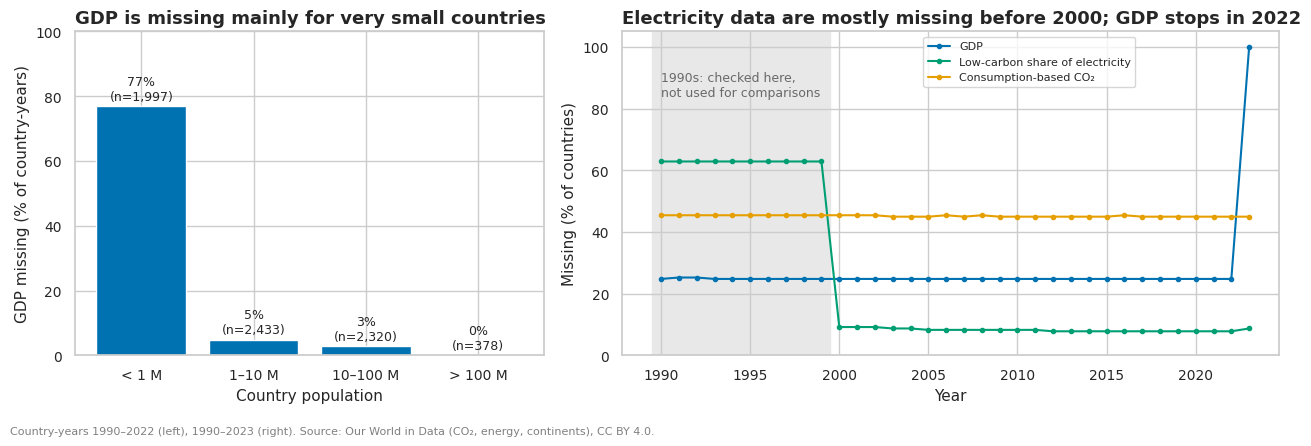

Countries without GDP/CO₂ for 2005 and 2022: 54; by continent: {'North America': 17, 'Oceania': 17, 'Europe': 6, 'Asia': 6, 'Africa': 5, 'South America': 2}
Median 2022 population of these countries: 103,558
Excluded countries with more than 5 million people: ['Papua New Guinea', 'Somalia', 'South Sudan', 'Sudan']


In [10]:
by_year = (panel.groupby("year")[["gdp", "low_carbon_share_elec", "consumption_co2"]]
           .apply(lambda d: d.isna().mean() * 100))
early = p22["year"] < ANALYSIS_START
elec_miss = {f"{YEAR_MIN}–{ANALYSIS_START - 1}": p22.loc[early, "low_carbon_share_elec"].isna().mean() * 100,
             f"{ANALYSIS_START}–2022": p22.loc[~early, "low_carbon_share_elec"].isna().mean() * 100}
print("Low-carbon share of electricity missing:", {per: f"{v:.1f}%" for per, v in elec_miss.items()})

# What a 1990 start would do: the early 1990s include the collapse of the Soviet economy.
t90 = decoupling_table(panel, YEAR_MIN, 2022).set_index("country")
post_soviet = ["Russia", "Belarus", "Romania", "Azerbaijan"]
print(f"{YEAR_MIN}→2022 labels:", t90.loc[post_soviet, "decoupling"].to_dict())
R["elec_mix_missing_pct"] = {per: round(float(v), 1) for per, v in elec_miss.items()}
R["labels_1990_2022_post_soviet"] = t90.loc[post_soviet, "decoupling"].to_dict()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.bar(by_size.index.astype(str), by_size.values, color="#0072B2")
for i, (v, n) in enumerate(zip(by_size.values, n_size.values)):
    ax.text(i, v + 2, f"{v:.0f}%\n(n={n:,})", ha="center", fontsize=9)
ax.set(ylim=(0, 100), xlabel="Country population", ylabel="GDP missing (% of country-years)",
       title="GDP is missing mainly for very small countries")
ax = axes[1]
ax.axvspan(YEAR_MIN - 0.5, ANALYSIS_START - 0.5, color="#E8E8E8", zorder=0)
ax.text(YEAR_MIN, 92, f"{YEAR_MIN}s: checked here,\nnot used for comparisons", fontsize=9, color="dimgrey", va="top")
labels = {"gdp": "GDP", "low_carbon_share_elec": "Low-carbon share of electricity",
          "consumption_co2": "Consumption-based CO₂"}
for col, color in zip(labels, ["#0072B2", "#009E73", "#E69F00"]):
    ax.plot(by_year.index, by_year[col], marker="o", ms=3, color=color, label=labels[col])
ax.set(ylim=(0, 105), xlabel="Year", ylabel="Missing (% of countries)",
       title=f"Electricity data are mostly missing before {ANALYSIS_START}; GDP stops in 2022")
ax.legend(loc="upper center", bbox_to_anchor=(0.62, 1.0), fontsize=8)
fig.text(0.01, -0.03, "Country-years 1990–2022 (left), 1990–2023 (right). " + SOURCE_NOTE, fontsize=8, color="grey")
plt.tight_layout(); save(fig, "fig02_missingness.png"); plt.show()

dec_tmp = decoupling_table(panel, 2005, 2022)
excluded = dec_tmp[dec_tmp["decoupling"] == "Insufficient data"]
big_excluded = excluded.loc[excluded["population_end"] > 5e6, "country"].tolist()
print(f"Countries without GDP/CO₂ for 2005 and 2022: {len(excluded)}; by continent:",
      excluded["continent"].value_counts().to_dict())
print(f"Median 2022 population of these countries: {excluded['population_end'].median():,.0f}")
print("Excluded countries with more than 5 million people:", big_excluded)
R["insufficient_data_2005_2022"] = {"n": int(len(excluded)),
                                    "by_continent": excluded["continent"].value_counts().to_dict(),
                                    "median_population_2022": float(excluded["population_end"].median()),
                                    "over_5m_people": big_excluded}


**Assessment.** CO₂ and population are almost complete. GDP is missing for about a quarter of country-years, but the
gaps are **structural, not random**: most are micro-states (Caribbean and Pacific islands, Monaco ...), a few are
larger countries hit by war or crisis (Sudan, Somalia, South Sudan, Papua New Guinea), and every country lacks GDP
after 2022. Electricity shares are missing for about 63% of country-years in the 1990s but for only about 8% from 2000 on.
Consumption-based CO₂ only exists for ~120 larger countries.

**Decision: comparisons start in 2000.** The panel keeps 1990–2023 so that the checks above can show the problem, but
every year choice in the analysis and in the app starts in 2000, for two reasons. (1) The electricity question cannot
be answered for most countries in the 1990s. (2) The early 1990s include the collapse of the Soviet economy: a
1990 → 2022 comparison labels Russia, Belarus, Romania and Azerbaijan as "decouplers" only because their heavy industry
collapsed first (printed above), which is not the story this project is about.

**Decision: do NOT impute GDP.** The decoupling label depends entirely on the *sign* of GDP growth; an imputed value
for a micro-state would create a verdict out of invented numbers, and since missingness depends on country size
(not missing at random), a simple fill would also be biased. Countries without GDP in both years are labelled
*Insufficient data* and shown as excluded (with n) instead. Because this group is small, often poor and partly
conflict-affected, the results describe mid-size and large, better-documented countries. Consumption CO₂ is likewise
not imputed; the offshoring check (Q4) uses only countries that have it.

### 2.6 Outliers
CO₂ per capita is very right-skewed, so I screen for outliers with a z-score on the **log10** scale.
Zero values cannot be logged and are set aside first.

In [11]:
cpc = panel["co2_per_capita"]
zeros = panel.loc[cpc == 0, ["country", "year"]]
pos = panel.loc[cpc > 0, ["country", "year", "co2_per_capita"]].copy()
pos["log10"] = np.log10(pos["co2_per_capita"])
pos["z"] = (pos["log10"] - pos["log10"].mean()) / pos["log10"].std()
flags = pos[pos["z"].abs() > 3]
print(f"Zero CO₂ per capita (excluded from log): {len(zeros)} rows ->",
      zeros.groupby("country")["year"].agg(list).to_dict())
print(f"Median CO₂ per capita: {cpc.median():.2f} t, max {cpc.max():.1f} t")
print(f"|z| > 3 on the log scale: {len(flags)} row(s)")
print(flags.round(2).to_string(index=False))
print("\nNext largest values:"); print(pos.nlargest(4, "co2_per_capita")[["country", "year", "co2_per_capita", "z"]]
                                      .round(2).to_string(index=False))
kw = flags.iloc[0]
R["outliers"] = {"co2_per_capita_median_t": round(float(cpc.median()), 2),
                 "co2_per_capita_max_t": round(float(cpc.max()), 1),
                 "n_zero_values_excluded_from_log": int(len(zeros)),
                 "n_abs_z_gt_3_log_scale": int(len(flags)),
                 "flagged": f"{kw['country']} {int(kw['year'])}",
                 "kuwait_1991_co2_per_capita_t": round(float(kw["co2_per_capita"]), 1),
                 "kuwait_1991_z_log": round(float(kw["z"]), 2),
                 "decision": "keep and annotate (real event: Gulf War oil-well fires)"}

Zero CO₂ per capita (excluded from log): 4 rows -> {'East Timor': [1994, 1995, 1996, 1997]}
Median CO₂ per capita: 2.73 t, max 364.8 t
|z| > 3 on the log scale: 1 row(s)
country  year  co2_per_capita  log10    z
 Kuwait  1991          364.79   2.56 3.25

Next largest values:
country  year  co2_per_capita    z
 Kuwait  1991          364.79 3.25
  Qatar  1997           76.72 2.28
  Qatar  2001           67.73 2.20
  Qatar  1996           65.16 2.17


saved docs/figures/fig03_co2_per_capita_outliers.png


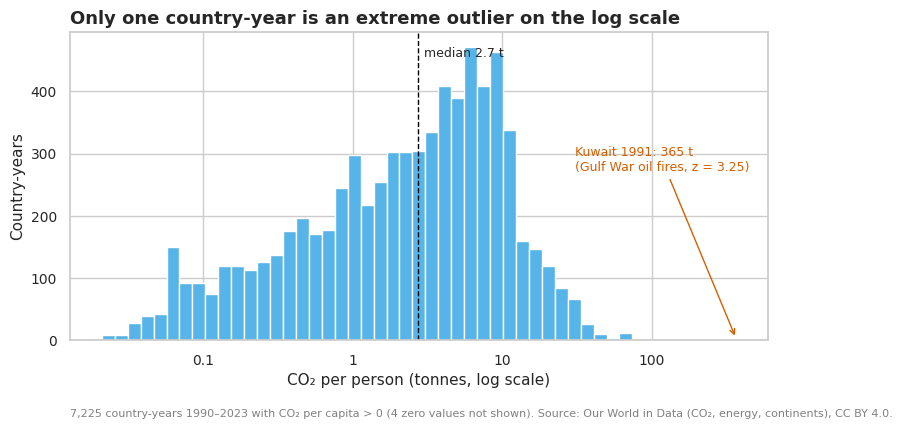

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.logspace(np.log10(pos["co2_per_capita"].min()), np.log10(pos["co2_per_capita"].max()), 50)
ax.hist(pos["co2_per_capita"], bins=bins, color="#56B4E9", edgecolor="white")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(PLAIN)
ax.axvline(cpc.median(), color="black", ls="--", lw=1)
ax.text(cpc.median() * 1.1, ax.get_ylim()[1] * 0.92, f"median {cpc.median():.1f} t", fontsize=9)
ax.annotate(f"Kuwait 1991: {kw['co2_per_capita']:.0f} t\n(Gulf War oil fires, z = {kw['z']:.2f})",
            xy=(kw["co2_per_capita"], 3), xytext=(kw["co2_per_capita"] / 12, ax.get_ylim()[1] * 0.55),
            arrowprops=dict(arrowstyle="->", color="#D55E00"), color="#D55E00", fontsize=9)
ax.set(xlabel="CO₂ per person (tonnes, log scale)", ylabel="Country-years",
       title="Only one country-year is an extreme outlier on the log scale")
ax.text(0, -0.25, f"{len(pos):,} country-years 1990–2023 with CO₂ per capita > 0 ({len(zeros)} zero values not shown). "
        + SOURCE_NOTE, transform=ax.transAxes, fontsize=8, color="grey")
save(fig, "fig03_co2_per_capita_outliers.png"); plt.show()

**Decision: keep Kuwait 1991 and annotate it.** It is a real event (the Gulf War oil-well fires), not a data error, so
deleting it would hide history. It does not affect the decoupling analysis (comparisons start in 2000), and
charts that show CO₂ per capita use a log axis so it does not squash everything else. The 4 zero values
(East Timor 1994–1997) are also kept in the data; they are only left out of log-scale views.

## 3. Feature engineering: the decoupling label

For each country and two chosen years *A → B* (`decoupling_table`, defined in Section 0):

$$\%\Delta \text{GDP} = \left(\frac{\text{GDP}_B}{\text{GDP}_A} - 1\right)\times 100, \qquad
\%\Delta \text{CO}_2 = \left(\frac{\text{CO}_{2,B}}{\text{CO}_{2,A}} - 1\right)\times 100$$

| Label | Rule |
|---|---|
| **Absolute decoupling** | %ΔGDP > 0 **and** %ΔCO₂ < −5 |
| **CO₂ about flat** | %ΔGDP > 0 and −5 ≤ %ΔCO₂ ≤ +5 |
| **Coupled growth** | %ΔGDP > 0 and %ΔCO₂ > +5 |
| **GDP fell** | %ΔGDP ≤ 0 |
| **Insufficient data** | GDP or CO₂ missing in year A or B (no imputation) |

**Why a ±5% margin?** Without one, a country whose CO₂ moved by a fraction of a percent (Australia: −0.3% between
2005 and 2022) would count as a "decoupler". A change that small is not a trend: it is within normal year-to-year
swings (a cold winter, one power plant closing) and within the uncertainty of the CO₂ estimates themselves (the Global
Carbon Project gives about ±5% even for the world total). The margin is a judgement call, so Section 4.5 repeats the
count with no margin and with ±10%.

Electricity-mix change is measured in **percentage points**: Δ low-carbon share = share_B − share_A (low-carbon =
nuclear + hydro + wind + solar + other renewables), and the same for coal. The same rule is applied to
consumption-based CO₂ (`cons_co2_change_pct`) for the offshoring check.

The function is defined once (Section 0) and used for every comparison in this notebook; `app.py` holds
the same function. The cell below re-computes the label by hand, as an independent check, and asserts both agree.

**Main comparison: 2005 → 2022.** 2005 is the year the Kyoto Protocol came into force and the EU started its
emissions-trading system, so it is a natural "climate policy starts" baseline; 2022 is the last year with GDP.
Section 4.5 tests other year pairs (all from 2000 on, see Section 2.5).

In [13]:
START, END = 2005, 2022
dec = decoupling_table(panel, START, END)

# Independent re-implementation as a check
a = panel[panel["year"] == START].set_index("iso_code")
b = panel[panel["year"] == END].set_index("iso_code")
gdp_chg = (b["gdp"] / a["gdp"] - 1) * 100
co2_chg = (b["co2"] / a["co2"] - 1) * 100
B = FLAT_BAND_PCT
manual = pd.Series("Coupled growth", index=gdp_chg.index)
manual[(gdp_chg > 0) & (co2_chg.abs() <= B)] = "CO₂ about flat"
manual[(gdp_chg > 0) & (co2_chg < -B)] = "Absolute decoupling"
manual[gdp_chg <= 0] = "GDP fell"
manual[gdp_chg.isna() | co2_chg.isna()] = "Insufficient data"
check = dec.set_index("iso_code")
assert (manual.reindex(check.index).fillna("Insufficient data") == check["decoupling"]).all()
assert np.allclose(gdp_chg.reindex(check.index), check["gdp_change_pct"], equal_nan=True)
print("Manual labels and % changes match decoupling_table ✔")

k = dec[dec["decoupling"] != "Insufficient data"].copy()   # countries that can be classified
counts = k["decoupling"].value_counts().reindex(CLASS_ORDER[:4])
print(f"\n{START}→{END}: {len(k)} of {len(dec)} countries can be classified")
print(counts.to_frame("n").assign(pct=(counts / counts.sum() * 100).round(1)).to_string())
k[["country", "continent", "gdp_change_pct", "co2_change_pct", "low_carbon_change_pp",
   "coal_change_pp", "decoupling"]].round(1).head()

Manual labels and % changes match decoupling_table ✔

2005→2022: 164 of 218 countries can be classified
                       n   pct
decoupling                    
Absolute decoupling   38  23.2
CO₂ about flat        11   6.7
Coupled growth       107  65.2
GDP fell               8   4.9


,country,continent,gdp_change_pct,co2_change_pct,low_carbon_change_pp,coal_change_pp,decoupling
0,Afghanistan,Asia,109.9,438.1,14.5,-4.2,Coupled growth
1,Albania,Europe,75.9,5.6,1.3,0.0,Coupled growth
2,Algeria,Africa,82.3,76.0,-0.7,0.0,Coupled growth
4,Angola,Africa,204.7,37.1,-8.8,0.0,Coupled growth
8,Argentina,South America,42.2,13.6,-5.6,-0.5,Coupled growth


## 4. Exploratory data analysis, question by question

Each chart answers one question; the title states the answer. Categories use the Okabe–Ito colour-blind-safe palette
(the same colours as the app). Group sizes *n* are shown because the classes are unbalanced.

### Q1. Did GDP and CO₂ move together or apart in a given country?
Indexing every series to **2005 = 100** (the start of the main comparison) puts GDP, CO₂ and population on the same scale without a second y-axis.

saved docs/figures/fig04_indexed_examples.png


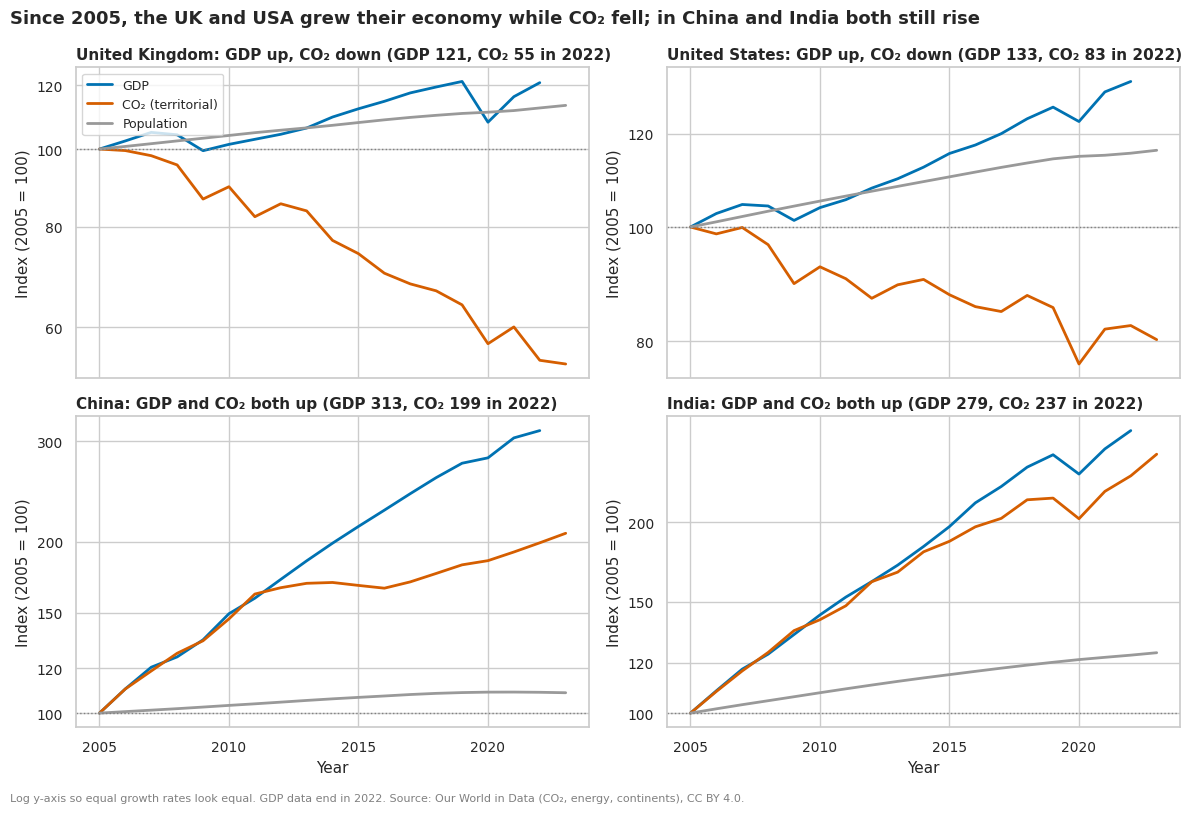

,gdp_index_2022,co2_index_2022
United Kingdom,121.0,54.5
United States,132.8,82.5
China,313.5,199.1
India,279.2,236.8


In [14]:
examples = {"GBR": "United Kingdom", "USA": "United States", "CHN": "China", "IND": "India"}
BASE = START
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
q1 = {}
for ax, (iso, name) in zip(axes.flat, examples.items()):
    d = panel[(panel["iso_code"] == iso) & (panel["year"] >= BASE)].set_index("year")
    idx = pd.DataFrame({lab: d[col] / d.loc[BASE, col] * 100
                        for lab, col in [("GDP", "gdp"), ("CO₂ (territorial)", "co2"), ("Population", "population")]})
    for lab in idx:
        ax.plot(idx.index, idx[lab], color=SERIES_COLORS[lab], lw=2, label=lab)
    ax.axhline(100, color="grey", ls=":", lw=1)
    last = idx["GDP"].last_valid_index()
    g, c_ = idx.loc[last, "GDP"], idx.loc[last, "CO₂ (territorial)"]
    verdict = ("GDP up, CO₂ down" if (g > 100 and c_ < 100 - FLAT_BAND_PCT) else
               "GDP up, CO₂ about flat" if (g > 100 and abs(c_ - 100) <= FLAT_BAND_PCT) else "GDP and CO₂ both up")
    ax.set_title(f"{name}: {verdict} (GDP {g:.0f}, CO₂ {c_:.0f} in {last})", fontsize=11)
    ax.set_ylabel(f"Index ({BASE} = 100)")
    ax.set_yscale("log")
    ticks = [40, 50, 60, 80, 100, 120, 150, 200, 300, 400]
    lo, hi = idx.min().min(), idx.max().max()
    ax.yaxis.set_major_locator(plt.FixedLocator([t for t in ticks if lo * 0.9 <= t <= hi * 1.1]))
    ax.yaxis.set_major_formatter(PLAIN)
    ax.yaxis.set_minor_locator(plt.NullLocator())
    q1[name] = {"gdp_index_2022": round(float(g), 1), "co2_index_2022": round(float(c_), 1)}
axes[0, 0].legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("Year")
    ax.set_xticks(range(BASE, 2023, 5))
fig.suptitle(f"Since {BASE}, the UK and USA grew their economy while CO₂ fell; in China and India both still rise",
             x=0.01, ha="left", fontsize=13, weight="bold")
fig.text(0.01, -0.01, "Log y-axis so equal growth rates look equal. GDP data end in 2022. " + SOURCE_NOTE,
         fontsize=8, color="grey")
plt.tight_layout(); save(fig, "fig04_indexed_examples.png"); plt.show()
R[f"q1_index_{BASE}_100"] = q1
pd.DataFrame(q1).T

**Reading.** Since 2005 the UK's GDP grew by about a fifth while its territorial CO₂ almost halved — a clear case of
absolute decoupling. The USA grew GDP by about a third while CO₂ fell by about 17%. China's and India's CO₂ still rose
strongly with GDP (China's CO₂ doubled while its GDP tripled), so their growth is still coupled to emissions, even though
CO₂ grows more slowly than GDP. I use a **log axis** here so that the same growth rate looks the same in all four
panels (China's GDP index reaches about 310). The app shows one country at a time on its own axis, so it uses a plain
(linear) axis, which is easier to read for a general audience.

### Q2. Which countries decoupled between 2005 and 2022?

saved docs/figures/fig05_decoupling_scatter.png


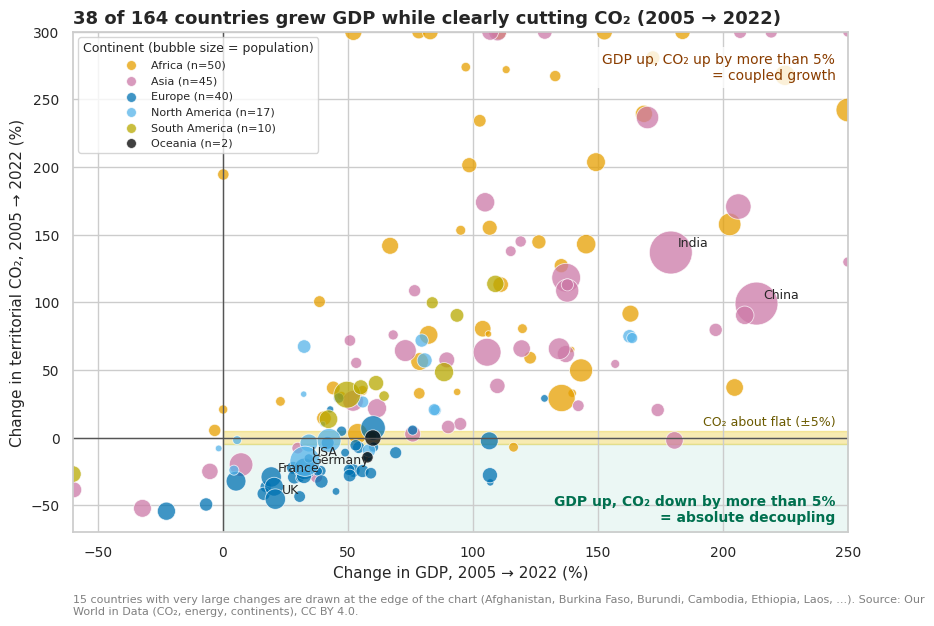

Spearman correlation of %ΔGDP and %ΔCO₂: rho = 0.71 (n = 164, p = 1.5e-26)
                     gdp_change_pct  co2_change_pct
decoupling                                         
Absolute decoupling            38.5           -24.6
CO₂ about flat                 53.9            -1.9
Coupled growth                106.2            76.0
GDP fell                      -14.6           -32.8


In [15]:
XL, YL = (-60, 250), (-70, 300)   # zoom on most countries; outliers listed in the footnote
B = FLAT_BAND_PCT
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.fill_between([0, XL[1]], YL[0], -B, color=CLASS_COLORS["Absolute decoupling"], alpha=0.08, zorder=0)
ax.fill_between([0, XL[1]], -B, B, color=CLASS_COLORS["CO₂ about flat"], alpha=0.3, zorder=0)
for cont, color in CONTINENT_COLORS.items():
    g = k[k["continent"] == cont]
    ax.scatter(g["gdp_change_pct"].clip(*XL), g["co2_change_pct"].clip(*YL),
               s=np.sqrt(g["population_end"]) / 40 + 10, color=color, alpha=0.75,
               edgecolor="white", linewidth=0.6, label=f"{cont} (n={len(g)})")
ax.axhline(0, color="#555555", lw=1); ax.axvline(0, color="#555555", lw=1)
ax.text(XL[1] - 5, YL[0] + 8, f"GDP up, CO₂ down by more than {B}%\n= absolute decoupling", ha="right",
        color="#00704f", fontsize=10, weight="bold")
ax.text(XL[1] - 5, B + 2, f"CO₂ about flat (±{B}%)", ha="right", va="bottom", color="#6b5a00", fontsize=9)
ax.text(XL[1] - 5, YL[1] - 15, f"GDP up, CO₂ up by more than {B}%\n= coupled growth", ha="right", va="top", color="#8a3d00", fontsize=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.8))
labels = {"GBR": "UK", "USA": "USA", "DEU": "Germany", "CHN": "China", "IND": "India", "FRA": "France"}
ki = k.set_index("iso_code")
for iso, lab in labels.items():
    r_ = ki.loc[iso]
    ax.annotate(lab, (min(r_["gdp_change_pct"], XL[1]), min(r_["co2_change_pct"], YL[1])),
                xytext=(5, 4), textcoords="offset points", fontsize=9)
off = k[~k["gdp_change_pct"].between(*XL) | ~k["co2_change_pct"].between(*YL)]
ax.set(xlim=XL, ylim=YL, xlabel=f"Change in GDP, {START} → {END} (%)",
       ylabel=f"Change in territorial CO₂, {START} → {END} (%)",
       title=f"{counts['Absolute decoupling']} of {len(k)} countries grew GDP while clearly cutting CO₂ ({START} → {END})")
leg = ax.legend(title="Continent (bubble size = population)", loc="upper left", fontsize=8, title_fontsize=9)
for h in leg.legend_handles:
    h.set_sizes([50])
ax.text(0, -0.16, f"{len(off)} countries with very large changes are drawn at the edge of the chart "
        f"({', '.join(off['country'].head(6))}{', ...' if len(off) > 6 else ''}). {SOURCE_NOTE}",
        transform=ax.transAxes, fontsize=8, color="grey", wrap=True)
save(fig, "fig05_decoupling_scatter.png"); plt.show()

rho, p_rho = stats.spearmanr(k["gdp_change_pct"], k["co2_change_pct"])
med_by_class = k.groupby("decoupling")[["gdp_change_pct", "co2_change_pct"]].median().round(1)
print(f"Spearman correlation of %ΔGDP and %ΔCO₂: rho = {rho:.2f} (n = {len(k)}, p = {p_rho:.1e})")
print(med_by_class.to_string())

saved docs/figures/fig06_class_by_continent.png


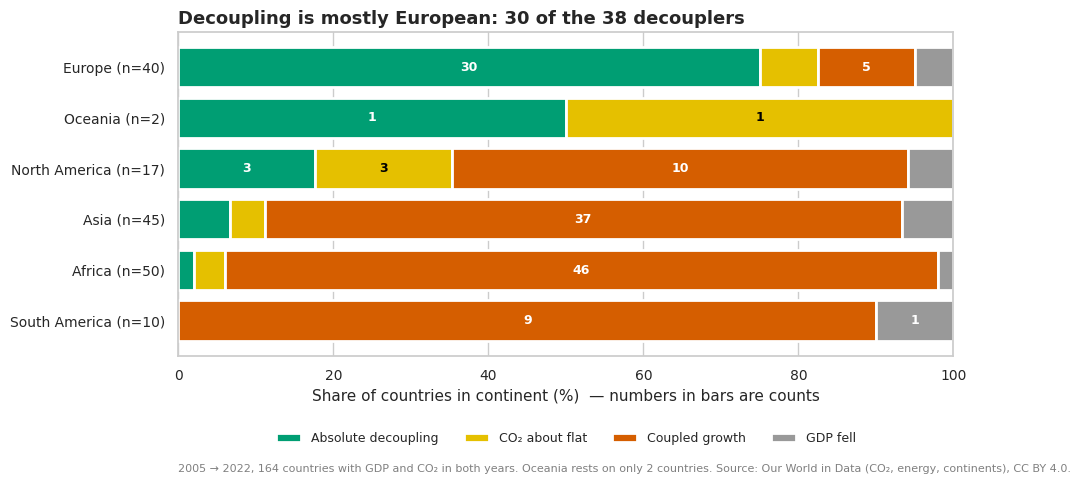

decoupling,Absolute decoupling,CO₂ about flat,Coupled growth,GDP fell,n
continent,,,,,
Africa,1,2,46,1,50
Asia,3,2,37,3,45
Europe,30,3,5,2,40
North America,3,3,10,1,17
Oceania,1,1,0,0,2
South America,0,0,9,1,10


In [16]:
ct = pd.crosstab(k["continent"], k["decoupling"]).reindex(columns=CLASS_ORDER[:4], fill_value=0)
n_cont = ct.sum(axis=1)
ct_pct = ct.div(n_cont, axis=0) * 100
order = ct_pct.sort_values("Absolute decoupling").index

fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(order))
for cls in CLASS_ORDER[:4]:
    vals = ct_pct.loc[order, cls].values
    ax.barh([f"{c_} (n={n_cont[c_]})" for c_ in order], vals, left=left, color=CLASS_COLORS[cls],
            edgecolor="white", linewidth=2, label=cls)
    for y, (l, v, cnt) in enumerate(zip(left, vals, ct.loc[order, cls])):
        if v >= 8:
            ax.text(l + v / 2, y, f"{cnt}", ha="center", va="center", fontsize=9, weight="bold",
                    color="black" if cls == "CO₂ about flat" else "white")
    left += vals
ax.set(xlim=(0, 100), xlabel="Share of countries in continent (%)  — numbers in bars are counts",
       title=f"Decoupling is mostly European: {ct.loc['Europe', 'Absolute decoupling']} of the "
             f"{counts['Absolute decoupling']} decouplers")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.grid(axis="y", visible=False)
ax.text(0, -0.36, f"{START} → {END}, {len(k)} countries with GDP and CO₂ in both years. Oceania rests on only "
        f"{n_cont.get('Oceania', 0)} countries. " + SOURCE_NOTE, transform=ax.transAxes, fontsize=8, color="grey")
save(fig, "fig06_class_by_continent.png"); plt.show()
ct.assign(n=n_cont)

In [17]:
is_dec = k["decoupling"] == "Absolute decoupling"
pop_share = k.loc[is_dec, "population_end"].sum() / k["population_end"].sum() * 100
co2_share = k.loc[is_dec, "co2_end"].sum() / k["co2_end"].sum() * 100
print(f"Decouplers are {is_dec.mean():.0%} of the {len(k)} countries, but hold {pop_share:.1f}% of their people "
      f"and {co2_share:.1f}% of their CO₂ in {END}")

R["main_period"] = {"start": START, "end": END}
R["decoupling_2005_2022"] = {
    "n_countries_total": int(len(dec)), "n_classified": int(len(k)),
    "n_insufficient_data": int((dec["decoupling"] == "Insufficient data").sum()),
    "counts": {cls: int(counts[cls]) for cls in counts.index},
    "pct_of_classified": {cls: round(float(counts[cls] / len(k) * 100), 1) for cls in counts.index},
    "decouplers_by_continent": ct["Absolute decoupling"].to_dict(),
    "classified_by_continent": n_cont.to_dict(),
    "class_by_continent_counts": {cont: row.to_dict() for cont, row in ct.iterrows()},
    "median_change_pct_by_class": {cls: row.to_dict() for cls, row in med_by_class.iterrows()},
    "share_of_population_end_pct": round(float(pop_share), 1), "share_of_co2_end_pct": round(float(co2_share), 1),
    "spearman_rho_gdp_vs_co2_change": round(float(rho), 2), "spearman_p": float(f"{p_rho:.2e}"),
    "decoupler_countries": sorted(k.loc[k["decoupling"] == "Absolute decoupling", "country"]),
    "example_countries": {lab: {"gdp_change_pct": round(float(ki.loc[iso, "gdp_change_pct"]), 1),
                                "co2_change_pct": round(float(ki.loc[iso, "co2_change_pct"]), 1),
                                "class": ki.loc[iso, "decoupling"]} for iso, lab in labels.items()},
}

Decouplers are 23% of the 164 countries, but hold 12.5% of their people and 24.7% of their CO₂ in 2022


**Reading.** Most countries are in the upper-right (GDP and CO₂ both rose), and %ΔGDP and %ΔCO₂ are strongly
correlated across countries. Just under a quarter sit in the green area below the ±5% band, and the classes are
**unbalanced** both overall (≈ 65% coupled growth, 23% decoupling, 7% CO₂ about flat, 5% GDP fell) and by continent:
three quarters of European countries decoupled (30 of 40) but only 1 of 50 African countries. Counted by **people**
instead of countries the group is even smaller: decouplers hold about 1 in 8 of the people in these 164 countries
(12.5%) and about a quarter of their CO₂ (24.7%), because the most populous countries (China, India) are in coupled
growth. Because this is a descriptive project (no model is trained), I do not resample; instead I compare
**within-continent proportions** and always show *n*.

### Q3. Did decouplers also make their electricity cleaner?

No coal power in 2005 or 2022: 78 countries, {'Coupled growth': 60, 'Absolute decoupling': 11, 'GDP fell': 5, 'CO₂ about flat': 2}


saved docs/figures/fig07_electricity_mix_by_class.png


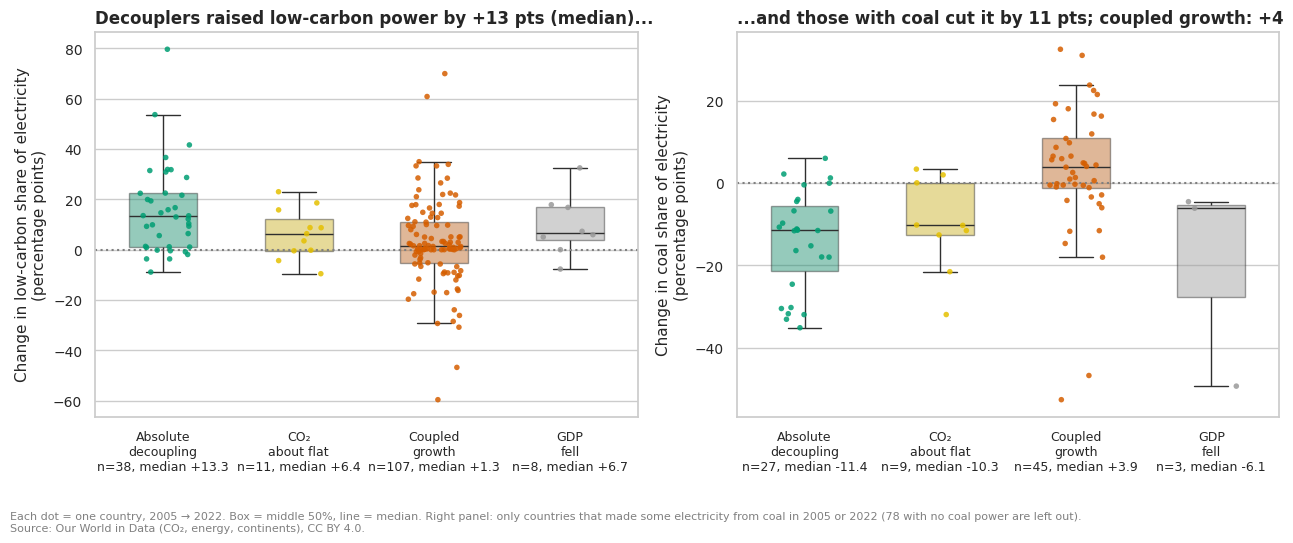

Mann-Whitney U (Absolute decoupling vs Coupled growth), low_carbon_change_pp: U = 2868, p = 1.8e-04, n = 38 vs 107
Mann-Whitney U (Absolute decoupling vs Coupled growth), coal_change_pp: U = 200, p = 2.2e-06, n = 27 vs 45


saved docs/figures/fig07b_electricity_europe_vs_rest.png


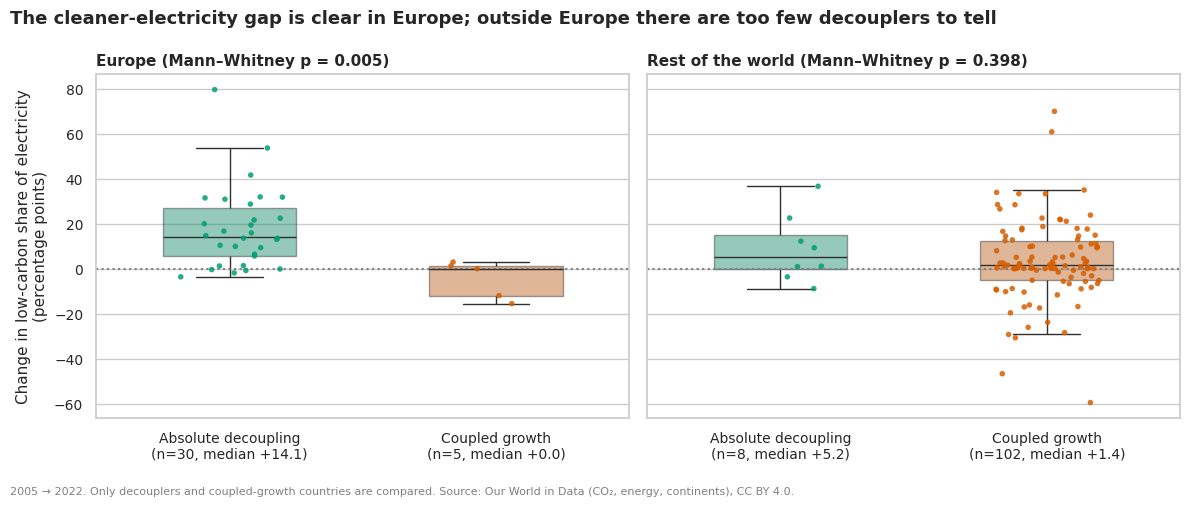

,n_decouplers,n_coupled,median_decouplers,median_coupled,mann_whitney_p
Europe,30.0,5.0,14.1,0.0,0.00474
Rest of the world,8.0,102.0,5.2,1.4,0.39800


In [18]:
order4 = CLASS_ORDER[:4]
D_, CG = "Absolute decoupling", "Coupled growth"
# Countries with no coal power in either year all sit at exactly 0 and would hide the real coal changes,
# so the coal panel only uses countries that made some electricity from coal in START or END.
no_coal = k[(k["coal_share_elec_start"] == 0) & (k["coal_share_elec_end"] == 0)]
coal_users = k.drop(no_coal.index)
print(f"No coal power in {START} or {END}: {len(no_coal)} countries,", no_coal["decoupling"].value_counts().to_dict())

panels = [(k, "low_carbon_change_pp", "Change in low-carbon share of electricity\n(percentage points)"),
          (coal_users, "coal_change_pp", "Change in coal share of electricity\n(percentage points)")]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
np.random.seed(830)   # fixed jitter so the saved figure is identical on every run
mix = {}
for ax, (data, col, lab) in zip(axes, panels):
    med, n_ = data.groupby("decoupling")[col].median(), data.groupby("decoupling")[col].count()
    mix[col] = (med, n_)
    sns.boxplot(data=data, x="decoupling", y=col, order=order4, hue="decoupling", palette=CLASS_COLORS, ax=ax,
                showfliers=False, width=0.5, boxprops=dict(alpha=0.45), legend=False)
    sns.stripplot(data=data, x="decoupling", y=col, order=order4, hue="decoupling", palette=CLASS_COLORS, ax=ax,
                  size=4, alpha=0.85, jitter=0.2, legend=False)
    ax.axhline(0, color="grey", ls=":")
    ax.set_xticks(range(len(order4)), [f"{o.replace(' ', chr(10), 1)}\nn={n_.get(o, 0)}, median {med.get(o, np.nan):+.1f}"
                                       for o in order4], fontsize=9)
    ax.set(xlabel="", ylabel=lab)
lc_med, lc_n = mix["low_carbon_change_pp"]
coal_med, coal_n = mix["coal_change_pp"]
axes[0].set_title(f"Decouplers raised low-carbon power by {lc_med[D_]:+.0f} pts (median)...", fontsize=12)
axes[1].set_title(f"...and those with coal cut it by {-coal_med[D_]:.0f} pts; coupled growth: {coal_med[CG]:+.0f}",
                  fontsize=12)
fig.text(0.01, -0.04, f"Each dot = one country, {START} → {END}. Box = middle 50%, line = median. Right panel: only countries "
         f"that made some electricity from coal in {START} or {END} ({len(no_coal)} with no coal power are left out).\n"
         + SOURCE_NOTE, fontsize=8, color="grey", va="top")
plt.tight_layout(); save(fig, "fig07_electricity_mix_by_class.png"); plt.show()

tests = {}
for data, col in [(k, "low_carbon_change_pp"), (coal_users, "coal_change_pp")]:
    x1, x2 = data.loc[data["decoupling"] == D_, col].dropna(), data.loc[data["decoupling"] == CG, col].dropna()
    u, p_u = stats.mannwhitneyu(x1, x2)
    tests[col] = {"U": float(u), "p": float(f"{p_u:.2e}"), "n": [int(len(x1)), int(len(x2))]}
    print(f"Mann-Whitney U ({D_} vs {CG}), {col}: U = {u:.0f}, p = {p_u:.1e}, n = {len(x1)} vs {len(x2)}")

# Is the electricity gap only a Europe effect? Same comparison inside and outside Europe.
k["region"] = np.where(k["continent"] == "Europe", "Europe", "Rest of the world")
by_region = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, reg in zip(axes, ["Europe", "Rest of the world"]):
    g = k[(k["region"] == reg) & k["decoupling"].isin([D_, CG])].dropna(subset=["low_carbon_change_pp"])
    x1 = g.loc[g["decoupling"] == D_, "low_carbon_change_pp"]
    x2 = g.loc[g["decoupling"] == CG, "low_carbon_change_pp"]
    u, p_u = stats.mannwhitneyu(x1, x2)
    by_region[reg] = {"n_decouplers": int(len(x1)), "n_coupled": int(len(x2)),
                      "median_decouplers": round(float(x1.median()), 1), "median_coupled": round(float(x2.median()), 1),
                      "mann_whitney_p": float(f"{p_u:.2e}")}
    sns.boxplot(data=g, x="decoupling", y="low_carbon_change_pp", order=[D_, CG], hue="decoupling",
                palette=CLASS_COLORS, ax=ax, showfliers=False, width=0.5, boxprops=dict(alpha=0.45), legend=False)
    sns.stripplot(data=g, x="decoupling", y="low_carbon_change_pp", order=[D_, CG], hue="decoupling",
                  palette=CLASS_COLORS, ax=ax, size=4, alpha=0.85, jitter=0.2, legend=False)
    ax.axhline(0, color="grey", ls=":")
    ax.set_xticks([0, 1], [f"{D_}\n(n={len(x1)}, median {x1.median():+.1f})",
                           f"{CG}\n(n={len(x2)}, median {x2.median():+.1f})"])
    ax.set(xlabel="", ylabel="Change in low-carbon share of electricity\n(percentage points)")
    ax.set_title(f"{reg} (Mann–Whitney p = {p_u:.3f})", fontsize=11)
fig.suptitle("The cleaner-electricity gap is clear in Europe; outside Europe there are too few decouplers to tell",
             x=0.01, ha="left", fontsize=13, weight="bold")
fig.text(0.01, -0.03, f"{START} → {END}. Only decouplers and coupled-growth countries are compared. " + SOURCE_NOTE, fontsize=8,
         color="grey")
plt.tight_layout(); save(fig, "fig07b_electricity_europe_vs_rest.png"); plt.show()

R["q3_electricity_mix_2005_2022"] = {
    "median_low_carbon_change_pp": lc_med.round(1).to_dict(), "n_low_carbon": lc_n.to_dict(),
    "median_coal_change_pp_coal_users": coal_med.round(1).to_dict(), "n_coal_users": coal_n.to_dict(),
    "n_no_coal_either_year": no_coal["decoupling"].value_counts().to_dict(),
    "mann_whitney_decoupling_vs_coupled": tests, "low_carbon_by_region": by_region}
pd.DataFrame(by_region).T


**Reading.** The typical decoupler increased its low-carbon electricity share by about 13 percentage points; for
coupled-growth countries the median change is close to zero (+1.3). For **coal** I only compare countries that actually
used coal: 78 countries had no coal power in either year and would all sit at exactly 0 (most of them are in the
coupled-growth group). Among coal users, decouplers cut coal's share by a median of about 11 points, while
coupled-growth countries *added* about 4. Mann–Whitney tests (chosen because the groups are small, unequal and skewed)
say both differences are unlikely to be chance.

**Is this just Europe?** Largely, yes. 30 of the 38 decouplers are European, so the pooled comparison is mostly Europe
vs. Africa and Asia. Inside Europe the gap is large and clear (+14 vs 0 points, p = 0.005). Outside Europe the
decouplers' median is also higher (+5 vs +1), but with only 8 decouplers the difference could be chance (p = 0.40).
So the honest statement is: *the cleaner-electricity pattern is clear in Europe; elsewhere there are too few
decouplers to tell.*

**How to read this.** Power-sector CO₂ is part of a country's total CO₂, so some link between cleaner electricity and
falling CO₂ is built in. The useful information is *which lever moved*: decouplers changed how they make electricity,
not only how much they use. The data cannot show that cleaner electricity *caused* the decoupling (efficiency,
deindustrialisation and the shift to services also matter), and the spread is wide — some decouplers barely changed
their mix.

### Q4. Is decoupling real, or did emissions just move abroad?
Territorial CO₂ counts emissions *inside* a country. Consumption-based CO₂ adds emissions embedded in imports and
removes those in exports. If a decoupler only cut territorial CO₂ by importing more goods, its consumption CO₂ would
not fall.

saved docs/figures/fig08_territorial_vs_consumption.png


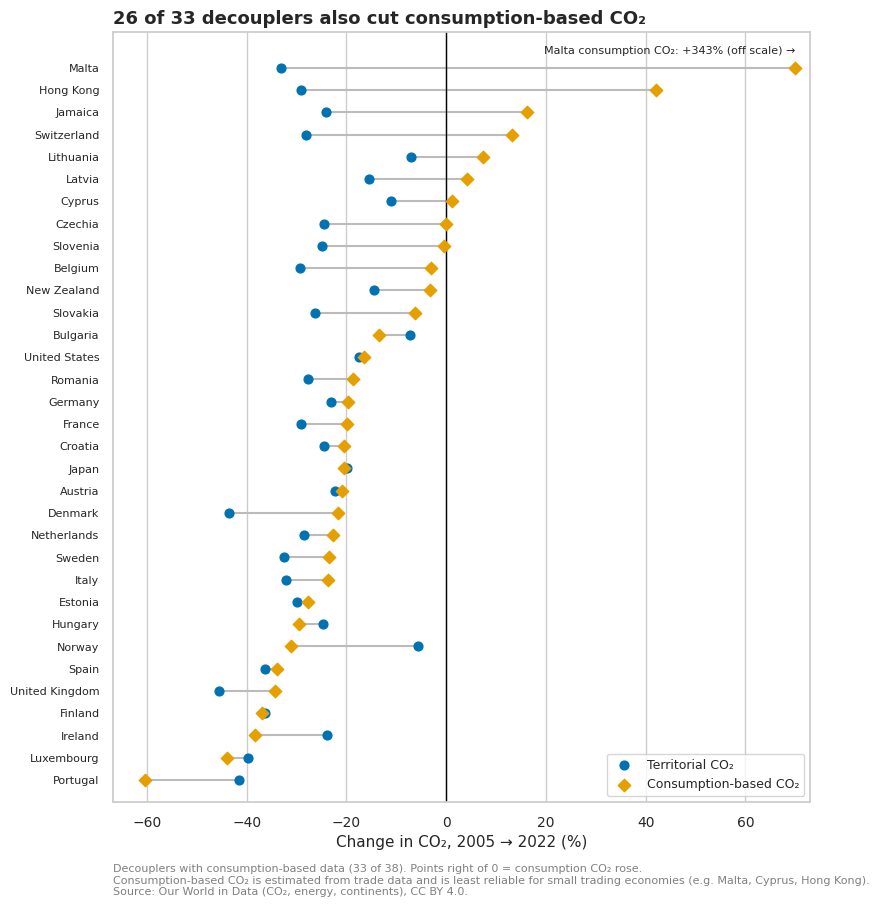

Decouplers whose consumption-based CO₂ did NOT fall (7):
    country  co2_change_pct  cons_co2_change_pct
     Cyprus           -11.1                  1.1
     Latvia           -15.4                  4.2
  Lithuania            -7.0                  7.5
Switzerland           -28.0                 13.3
    Jamaica           -24.1                 16.1
  Hong Kong           -29.0                 42.0
      Malta           -33.1                342.6


In [19]:
dcp = k[k["decoupling"] == "Absolute decoupling"]
cons = dcp.dropna(subset=["cons_co2_change_pct"]).sort_values("cons_co2_change_pct")
n_cons, n_cut = len(cons), int((cons["cons_co2_change_pct"] < 0).sum())

XMAX = 70   # one extreme value (Malta) is drawn at the edge and labelled, so the rest stay readable
cons_x = cons["cons_co2_change_pct"].clip(upper=XMAX)
fig, ax = plt.subplots(figsize=(9, 10))
y = np.arange(len(cons))
ax.hlines(y, cons["co2_change_pct"], cons_x, color="#BBBBBB", lw=1.5)
ax.scatter(cons["co2_change_pct"], y, color=CO2_KIND_COLORS["Territorial CO₂"], s=40, label="Territorial CO₂",
           zorder=3)
ax.scatter(cons_x, y, color=CO2_KIND_COLORS["Consumption-based CO₂"], s=40, marker="D",
           label="Consumption-based CO₂", zorder=3)
for yi, (_, r_) in zip(y, cons.iterrows()):
    if r_["cons_co2_change_pct"] > XMAX:
        ax.text(XMAX, yi + 0.55, f"{r_['country']} consumption CO₂: {r_['cons_co2_change_pct']:+.0f}% (off scale) →",
                ha="right", va="bottom", fontsize=8)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, cons["country"], fontsize=8)
ax.set(xlabel=f"Change in CO₂, {START} → {END} (%)", ylim=(-1, len(cons) + 0.6), xlim=(None, XMAX + 3),
       title=f"{n_cut} of {n_cons} decouplers also cut consumption-based CO₂")
ax.legend(loc="lower right")
ax.text(0, -0.08, f"Decouplers with consumption-based data ({n_cons} of {len(dcp)}). Points right of 0 = consumption "
        f"CO₂ rose.\nConsumption-based CO₂ is estimated from trade data and is least reliable for small trading economies "
        f"(e.g. Malta, Cyprus, Hong Kong).\n" + SOURCE_NOTE, transform=ax.transAxes, fontsize=8, color="grey", va="top")
ax.grid(axis="y", visible=False)
save(fig, "fig08_territorial_vs_consumption.png"); plt.show()

rose = cons.loc[cons["cons_co2_change_pct"] >= 0, ["country", "co2_change_pct", "cons_co2_change_pct"]].round(1)
print(f"Decouplers whose consumption-based CO₂ did NOT fall ({len(rose)}):"); print(rose.to_string(index=False))
R["q4_consumption_check_2005_2022"] = {
    "n_decouplers": int(len(dcp)), "n_with_consumption_data": int(n_cons),
    "n_also_cut_consumption_co2": n_cut, "pct_also_cut": round(n_cut / n_cons * 100, 1),
    "countries_consumption_rose": rose["country"].tolist(),
    "median_territorial_change_pct": round(float(cons["co2_change_pct"].median()), 1),
    "median_consumption_change_pct": round(float(cons["cons_co2_change_pct"].median()), 1)}

**Reading.** For most decouplers (about 8 in 10: 26 of the 33 with data), consumption-based CO₂ fell too, usually by a
little less than territorial CO₂ — so part of the improvement is offset by imports, but most of it is not just
"exported emissions". For the other 7 the decoupling disappears on a consumption basis, and the app's Limitations tab
says so. One caution: consumption-based CO₂ is *estimated* from trade statistics and is least reliable for small, very
open trading economies. Malta's consumption CO₂ more than quadrupled on paper (+343%) while its territorial CO₂ fell by
a third; Hong Kong and Cyprus are similar trade hubs. I keep them, but I would not draw a conclusion from any single one
of these countries.

### 4.5 Robustness: does the verdict depend on the years chosen?
A two-year comparison can be distorted by an unusual year. I repeat the classification for four year pairs that avoid
the 2020 COVID dip: **2000→2022, 2005→2022, 2010→2019, 2010→2022**.

                     2000→2022  2005→2022  2010→2019  2010→2022
Absolute decoupling         35         38         35         40
CO₂ about flat              10         11         25         15
Coupled growth             113        107         94         96
GDP fell                     6          8         10         13
Insufficient data            0          0          0          0

Of 164 countries (classified in 2005→2022): 164 classified in all four pairs, 119 keep the same label in all four (73%), 45 change at least once.
28 countries are decouplers in all four pairs.
Median |%ΔCO₂| 2005→2022: 11% for countries that switch label vs 66% for stable ones

2005→2022 with different margins:
                     no margin  ±5%  ±10%
decoupling                               
Absolute decoupling         45   38    32
CO₂ about flat               0   11    20
Coupled growth             111  107   104
GDP fell                     8    8     8
Decouplers in Europe: {'no margin': 32, '±5%': 30,

saved docs/figures/fig09_robustness_year_pairs.png


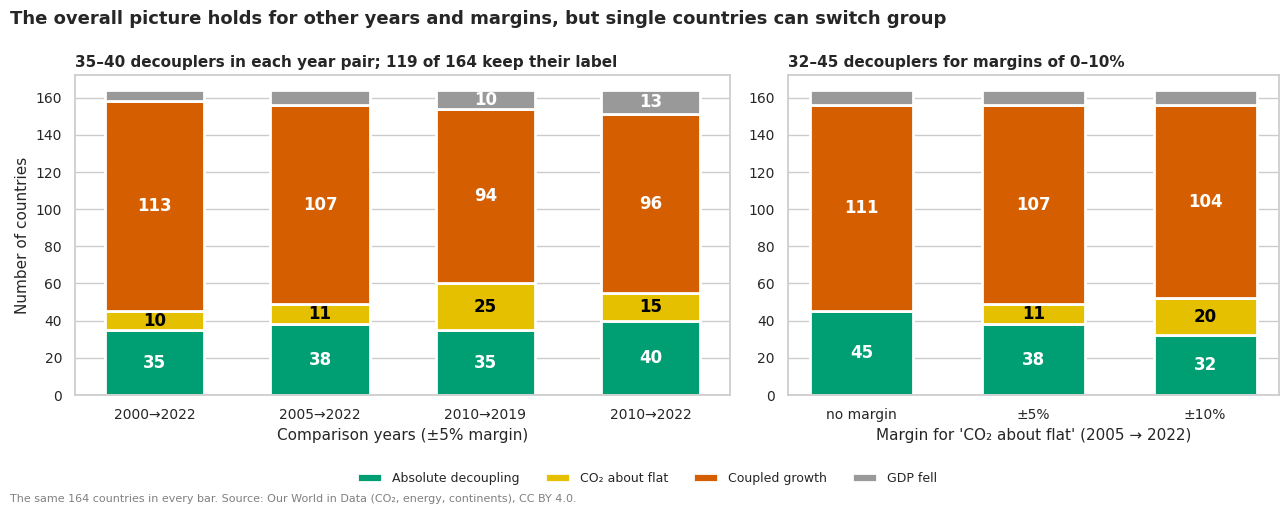

In [20]:
PAIRS = [(2000, 2022), (2005, 2022), (2010, 2019), (2010, 2022)]
labels_by_pair = pd.DataFrame({f"{s}→{e_}": decoupling_table(panel, s, e_).set_index("iso_code")["decoupling"]
                               for s, e_ in PAIRS})
base_known = labels_by_pair.index[labels_by_pair[f"{START}→{END}"] != "Insufficient data"]
lp = labels_by_pair.loc[base_known]
all_known = (lp != "Insufficient data").all(axis=1)
same = lp.nunique(axis=1) == 1
always_dec = (lp == "Absolute decoupling").all(axis=1)
pair_counts = lp.apply(lambda s: s.value_counts()).reindex(CLASS_ORDER).fillna(0).astype(int)
print(pair_counts.to_string())
print(f"\nOf {len(lp)} countries (classified in {START}→{END}): {all_known.sum()} classified in all four pairs, "
      f"{same.sum()} keep the same label in all four ({same.mean():.0%}), {len(lp) - same.sum()} change at least once.")
print(f"{always_dec.sum()} countries are decouplers in all four pairs.")
base_chg = dec.set_index("iso_code").loc[lp.index, "co2_change_pct"].abs()
print(f"Median |%ΔCO₂| 2005→2022: {base_chg[~same].median():.0f}% for countries that switch label vs "
      f"{base_chg[same].median():.0f}% for stable ones")

# Same period, different margins for "about flat"
BANDS = [0, FLAT_BAND_PCT, 10]
band_name = {b: ("no margin" if b == 0 else f"±{b}%") for b in BANDS}
band_tables = {b: decoupling_table(panel, START, END, band=b) for b in BANDS}
band_counts = pd.DataFrame({band_name[b]: t_["decoupling"].value_counts() for b, t_ in band_tables.items()}
                           ).reindex(CLASS_ORDER[:4]).fillna(0).astype(int)
band_europe = {band_name[b]: int(((t_["decoupling"] == "Absolute decoupling") & (t_["continent"] == "Europe")).sum())
               for b, t_ in band_tables.items()}
print(f"\n{START}→{END} with different margins:"); print(band_counts.to_string())
print("Decouplers in Europe:", band_europe)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [4, 3]})
for ax, cdf, xlab in [(axes[0], pair_counts.loc[CLASS_ORDER[:4]], f"Comparison years (±{FLAT_BAND_PCT}% margin)"),
                      (axes[1], band_counts, f"Margin for 'CO₂ about flat' ({START} → {END})")]:
    x = np.arange(cdf.shape[1])
    bottom = np.zeros(cdf.shape[1])
    for cls in CLASS_ORDER[:4]:
        vals = cdf.loc[cls].values
        ax.bar(x, vals, bottom=bottom, color=CLASS_COLORS[cls], edgecolor="white", linewidth=2, width=0.6, label=cls)
        for i, (b_, v) in enumerate(zip(bottom, vals)):
            if v >= 10:
                ax.text(i, b_ + v / 2, str(v), ha="center", va="center", weight="bold",
                        color="black" if cls == "CO₂ about flat" else "white")
        bottom += vals
    ax.set_xticks(x, cdf.columns)
    ax.set(xlabel=xlab)
    ax.grid(axis="x", visible=False)
axes[0].set(ylabel="Number of countries")
axes[0].set_title(f"{pair_counts.loc['Absolute decoupling'].min()}–{pair_counts.loc['Absolute decoupling'].max()} "
                  f"decouplers in each year pair; {same.sum()} of {len(lp)} keep their label", fontsize=11)
axes[1].set_title(f"{band_counts.loc['Absolute decoupling'].min()}–{band_counts.loc['Absolute decoupling'].max()} "
                  f"decouplers for margins of 0–10%", fontsize=11)
handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 0.0), frameon=False)
fig.suptitle("The overall picture holds for other years and margins, but single countries can switch group",
             x=0.01, ha="left", fontsize=13, weight="bold")
fig.text(0.01, -0.09, f"The same {len(lp)} countries in every bar. " + SOURCE_NOTE, fontsize=8, color="grey")
plt.tight_layout(); save(fig, "fig09_robustness_year_pairs.png"); plt.show()

R["robustness"] = {
    "year_pairs": [f"{s}-{e_}" for s, e_ in PAIRS],
    "n_countries": int(len(lp)), "n_classified_in_all_pairs": int(all_known.sum()),
    "decouplers_per_pair": {f"{s}-{e_}": int(pair_counts.loc["Absolute decoupling", f"{s}→{e_}"]) for s, e_ in PAIRS},
    "counts_per_pair": {col.replace("→", "-"): pair_counts[col].to_dict() for col in pair_counts},
    "n_same_label_all_pairs": int(same.sum()), "pct_same_label": round(float(same.mean() * 100), 1),
    "n_change_label": int(len(lp) - same.sum()), "pct_change_label": round(float((1 - same.mean()) * 100), 1),
    "n_decoupler_in_all_pairs": int(always_dec.sum()),
    "median_abs_co2_change_pct_switchers": round(float(base_chg[~same].median()), 1),
    "median_abs_co2_change_pct_stable": round(float(base_chg[same].median()), 1),
    "always_decouplers": sorted(panel.drop_duplicates("iso_code").set_index("iso_code")
                                .loc[always_dec[always_dec].index, "country"]),
    "margins": {band_name[b]: band_counts[band_name[b]].to_dict() for b in BANDS},
    "margins_decouplers_in_europe": band_europe}


**Reading.** The number of decouplers stays in a narrow band across year pairs (35–40), and about 3 in 4 countries
(119 of 164) keep exactly the same label in all four. The ones that switch are mostly countries whose CO₂ barely moved
(median change about ±11% vs ±66% for stable countries), so a small shift in the years moves them across a group
border. Changing the margin has a similar, limited effect: 45 decouplers with no margin, 38 with ±5% and 32 with ±10%,
and Europe is the large majority in every version (32, 30 and 27). So the overall picture is robust, but an individual
country's label can depend on the years and the margin chosen — which is why the app lets users change both and warns
about 2020.

### Supporting concept: how strongly does CO₂ per person rise with income?
A cross-section of countries in 2022, on log–log axes (both variables are right-skewed), with a simple OLS fit.
The slope is an *elasticity*: +1% GDP per person goes with about +slope% CO₂ per person *across countries*.

saved docs/figures/fig10_co2_vs_gdp_per_capita_loglog.png


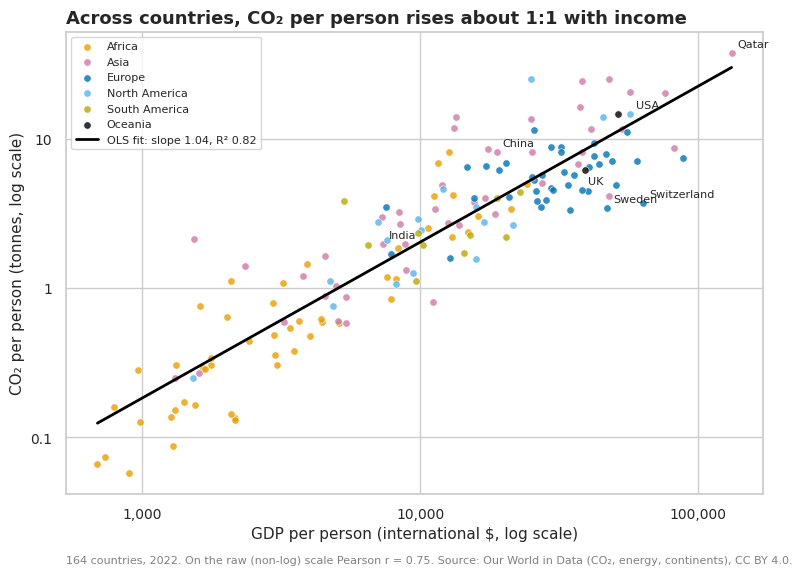

log10(CO₂ pc) = -3.87 + 1.04 · log10(GDP pc);  R² = 0.82;  95% CI slope [0.97, 1.12];  n = 164
Lowest CO₂ for their income (largest negative residuals): ['Switzerland', 'Uganda', 'Ethiopia', 'Sweden', 'Sri Lanka']


In [21]:
y22 = panel[panel["year"] == 2022].dropna(subset=["gdp_per_capita", "co2_per_capita"])
y22 = y22[y22["co2_per_capita"] > 0]
lx, ly = np.log10(y22["gdp_per_capita"]), np.log10(y22["co2_per_capita"])
fit = stats.linregress(lx, ly)
r_raw = stats.pearsonr(y22["gdp_per_capita"], y22["co2_per_capita"])[0]
resid = ly - (fit.intercept + fit.slope * lx)

fig, ax = plt.subplots(figsize=(9, 6))
for cont, color in CONTINENT_COLORS.items():
    g = y22[y22["continent"] == cont]
    ax.scatter(g["gdp_per_capita"], g["co2_per_capita"], s=28, color=color, alpha=0.8, edgecolor="white",
               linewidth=0.5, label=cont)
xs = np.logspace(lx.min(), lx.max(), 50)
ax.plot(xs, 10 ** (fit.intercept + fit.slope * np.log10(xs)), color="black", lw=2,
        label=f"OLS fit: slope {fit.slope:.2f}, R² {fit.rvalue**2:.2f}")
ax.set(xscale="log", yscale="log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(PLAIN)
ax.set(xlabel="GDP per person (international $, log scale)",
       ylabel="CO₂ per person (tonnes, log scale)",
       title=f"Across countries, CO₂ per person rises about 1:1 with income")
for iso, lab in {"USA": "USA", "GBR": "UK", "CHN": "China", "IND": "India", "QAT": "Qatar",
                 "SWE": "Sweden", "CHE": "Switzerland"}.items():
    r_ = y22.set_index("iso_code").loc[iso]
    ax.annotate(lab, (r_["gdp_per_capita"], r_["co2_per_capita"]), xytext=(4, 4), textcoords="offset points",
                fontsize=8)
ax.legend(loc="upper left", fontsize=8)
ax.text(0, -0.15, f"{len(y22)} countries, 2022. On the raw (non-log) scale Pearson r = {r_raw:.2f}. " + SOURCE_NOTE,
        transform=ax.transAxes, fontsize=8, color="grey")
save(fig, "fig10_co2_vs_gdp_per_capita_loglog.png"); plt.show()

ci = (fit.slope - 1.96 * fit.stderr, fit.slope + 1.96 * fit.stderr)
low_res = y22.assign(resid=resid.values).nsmallest(5, "resid")["country"].tolist()
print(f"log10(CO₂ pc) = {fit.intercept:.2f} + {fit.slope:.2f} · log10(GDP pc);  R² = {fit.rvalue**2:.2f};  "
      f"95% CI slope [{ci[0]:.2f}, {ci[1]:.2f}];  n = {len(y22)}")
print("Lowest CO₂ for their income (largest negative residuals):", low_res)
R["regression_log_co2pc_on_log_gdppc_2022"] = {
    "n": int(len(y22)), "slope": round(float(fit.slope), 2), "intercept": round(float(fit.intercept), 2),
    "r_squared": round(float(fit.rvalue ** 2), 2), "slope_95ci": [round(ci[0], 2), round(ci[1], 2)],
    "pearson_r_raw_scale": round(float(r_raw), 2), "pearson_r_log_scale": round(float(fit.rvalue), 2),
    "lowest_co2_for_income": low_res}

**Reading.** Richer countries emit more per person, roughly in proportion (slope ≈ 1), and income alone explains
about 80% of the variation on the log scale. The log transform is what makes this a clean straight line; on the raw
scale a few rich oil states dominate. This is the "default" relationship that decoupling has to beat: countries such
as Sweden and Switzerland sit well below the line, i.e. they are rich with low emissions — the same countries that show
up as decouplers in Q2. A cross-section says nothing about what happens *within* a country over time, which is why the
main analysis uses changes between years.

## 5. Key results summary

In [22]:
D = R["decoupling_2005_2022"]; Q3 = R["q3_electricity_mix_2005_2022"]; Q4 = R["q4_consumption_check_2005_2022"]
RB = R["robustness"]; RG = R["regression_log_co2pc_on_log_gdppc_2022"]
summary = pd.DataFrame([
    ["Data", "Countries × years in panel (1990–2023)", f"{R['join']['panel_countries']} countries, {R['join']['panel_rows']:,} rows"],
    ["Data", "Join (matched / CO₂-only / energy-only rows)",
     f"{R['join']['matched_rows']:,} / {R['join']['co2_only_rows']} / {R['join']['energy_only_rows']}"],
    ["Data", "Aggregate rows removed (CO₂ file)", f"{R['aggregates']['co2_rows_without_iso']:,}"],
    ["Data", "GDP missing (1990–2022) / for countries < 1 M people",
     f"{R['missingness_pct_1990_2022']['gdp']}% / {R['gdp_missing_pct_by_population']['< 1 M']}%"],
    ["Data", "Outlier (|z| > 3, log CO₂ per capita)",
     f"{R['outliers']['flagged']}: {R['outliers']['kuwait_1991_co2_per_capita_t']} t (z = {R['outliers']['kuwait_1991_z_log']})"],
    ["Q2", "Absolute decouplers 2005→2022", f"{D['counts']['Absolute decoupling']} of {D['n_classified']}"],
    ["Q2", "… of which in Europe", f"{D['decouplers_by_continent'].get('Europe', 0)}"],
    ["Q2", "CO₂ about flat / coupled growth / GDP fell",
     f"{D['counts']['CO₂ about flat']} / {D['counts']['Coupled growth']} / {D['counts']['GDP fell']}"],
    ["Q2", "Decouplers' share of people / of CO₂ in 2022",
     f"{D['share_of_population_end_pct']}% / {D['share_of_co2_end_pct']}%"],
    ["Q3", "Median Δ low-carbon share: decouplers vs coupled growth",
     f"{Q3['median_low_carbon_change_pp']['Absolute decoupling']:+.1f} vs {Q3['median_low_carbon_change_pp']['Coupled growth']:+.1f} pp"],
    ["Q3", "… inside Europe / outside Europe (Mann–Whitney p)",
     " / ".join(f"{v['median_decouplers']:+.1f} vs {v['median_coupled']:+.1f} (p = {v['mann_whitney_p']:.3f})"
                for v in Q3["low_carbon_by_region"].values())],
    ["Q3", "Median Δ coal share, countries with coal: decouplers vs coupled growth",
     f"{Q3['median_coal_change_pp_coal_users']['Absolute decoupling']:+.1f} vs {Q3['median_coal_change_pp_coal_users']['Coupled growth']:+.1f} pp"],
    ["Q4", "Decouplers that also cut consumption-based CO₂",
     f"{Q4['n_also_cut_consumption_co2']} of {Q4['n_with_consumption_data']}"],
    ["Robustness", "Decouplers across 4 year pairs",
     f"{min(RB['decouplers_per_pair'].values())}–{max(RB['decouplers_per_pair'].values())}"],
    ["Robustness", "Countries with the same label in all 4 pairs", f"{RB['n_same_label_all_pairs']} of {RB['n_countries']}"],
    ["Robustness", "Decouplers with no margin / ±5% / ±10%",
     " / ".join(str(v["Absolute decoupling"]) for v in RB["margins"].values())],
    ["Concept", "log CO₂ pc ~ log GDP pc (2022)", f"slope {RG['slope']}, R² {RG['r_squared']}"],
], columns=["Area", "Result", "Value"])
summary.style.hide(axis="index")

Area,Result,Value
Data,Countries × years in panel (1990–2023),"218 countries, 7,412 rows"
Data,Join (matched / CO₂-only / energy-only rows),"6,931 / 481 / 476"
Data,Aggregate rows removed (CO₂ file),"7,931"
Data,GDP missing (1990–2022) / for countries < 1 M people,24.8% / 76.9%
Data,"Outlier (|z| > 3, log CO₂ per capita)",Kuwait 1991: 364.8 t (z = 3.25)
Q2,Absolute decouplers 2005→2022,38 of 164
Q2,… of which in Europe,30
Q2,CO₂ about flat / coupled growth / GDP fell,11 / 107 / 8
Q2,Decouplers' share of people / of CO₂ in 2022,12.5% / 24.7%
Q3,Median Δ low-carbon share: decouplers vs coupled growth,+13.3 vs +1.3 pp


In [23]:
R["generated_by"] = "notebooks/energy_transition_analysis.ipynb"
R["generated_at"] = datetime.now().strftime("%Y-%m-%d %H:%M")
R["figures"] = sorted(p.name for p in FIG_DIR.glob("fig*.png"))
R["headline"] = {
    "n_decouplers_2005_2022": D["counts"]["Absolute decoupling"], "n_classified_2005_2022": D["n_classified"],
    "n_decouplers_europe": int(D["decouplers_by_continent"].get("Europe", 0)),
    "n_about_flat": D["counts"]["CO₂ about flat"],
    "n_coupled_growth": D["counts"]["Coupled growth"], "n_gdp_fell": D["counts"]["GDP fell"],
    "decouplers_share_of_population_pct": D["share_of_population_end_pct"],
    "decouplers_share_of_co2_pct": D["share_of_co2_end_pct"],
    "median_low_carbon_change_pp_decouplers": Q3["median_low_carbon_change_pp"]["Absolute decoupling"],
    "median_low_carbon_change_pp_coupled": Q3["median_low_carbon_change_pp"]["Coupled growth"],
    "low_carbon_by_region": Q3["low_carbon_by_region"],
    "median_coal_change_pp_decouplers_with_coal": Q3["median_coal_change_pp_coal_users"]["Absolute decoupling"],
    "median_coal_change_pp_coupled_with_coal": Q3["median_coal_change_pp_coal_users"]["Coupled growth"],
    "decouplers_by_margin": {m: v["Absolute decoupling"] for m, v in RB["margins"].items()},
    "decouplers_also_cut_consumption": f"{Q4['n_also_cut_consumption_co2']} of {Q4['n_with_consumption_data']}",
    "robust_same_label": f"{RB['n_same_label_all_pairs']} of {RB['n_countries']}",
    "regression_slope": RG["slope"], "regression_r2": RG["r_squared"],
}


def to_builtin(o):
    if isinstance(o, dict):
        return {str(key): to_builtin(v) for key, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_builtin(v) for v in o]
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    return o


out = ROOT / "docs" / "results.json"
out.write_text(json.dumps(to_builtin(R), indent=2, ensure_ascii=False))
print(f"wrote {out.relative_to(ROOT)} with {len(R)} top-level keys:", list(R))

wrote docs/results.json with 28 top-level keys: ['data_files', 'licence', 'unit_of_observation', 'analysis_years', 'comparisons_from_year', 'flat_band_pct', 'aggregates', 'join', 'consistency_checks', 'missingness_pct_1990_2022', 'gdp_last_year', 'gdp_missing_pct_by_population', 'gdp_missing_rows_share_small_countries_pct', 'elec_mix_missing_pct', 'labels_1990_2022_post_soviet', 'insufficient_data_2005_2022', 'outliers', 'q1_index_2005_100', 'main_period', 'decoupling_2005_2022', 'q3_electricity_mix_2005_2022', 'q4_consumption_check_2005_2022', 'robustness', 'regression_log_co2pc_on_log_gdppc_2022', 'generated_by', 'generated_at', 'figures', 'headline']


## 6. Limitations

- **Mostly a European story.** 30 of the 38 decouplers are in Europe. The link with cleaner electricity is clear there,
  but outside Europe there are too few decouplers (8) to say whether the same pattern holds.
- **Counted by country, not by people.** Each country counts once, whatever its size. Decouplers are just under a
  quarter of the countries but hold only about 1 in 8 of the people (and a quarter of the CO₂).
- **The ±5% margin is a judgement call.** It stops tiny changes from counting as decoupling; with no margin or with ±10%
  the count is 45 or 32 (Section 4.5). The label also cannot tell *why* CO₂ fell: a few decouplers cut CO₂ during an
  economic or energy crisis rather than a planned transition (e.g. Lebanon, whose economy collapsed after 2019).
- **Territorial vs. consumption CO₂.** The label uses territorial emissions. A country can lower them by importing
  carbon-heavy goods. Q4 shows that most decouplers with consumption data also cut consumption CO₂, but 7 did not,
  5 of the 38 have no consumption data, and the consumption estimates are uncertain for small trading economies
  (Malta, Hong Kong, Cyprus).
- **GDP gaps.** GDP is missing for most micro-states (77% of country-years for countries under 1 million people), for
  a few larger war-affected countries (Sudan, Somalia, South Sudan, Papua New Guinea), and after 2022. These countries
  are *Insufficient data*, so Oceania and the Caribbean are badly under-represented (Oceania: 2 classified countries)
  and the results describe mid-size and large, better-documented countries.
- **Endpoint sensitivity.** A two-year comparison ignores what happens in between. About 1 in 4 countries changes label
  across the four year pairs, and 2020 (COVID) lowered both GDP and CO₂, so it should be avoided as an endpoint.
  Comparisons start in 2000 because electricity data are mostly missing before then and the early 1990s mix in the
  post-Soviet economic collapse.
- **Observational, not causal.** Cleaner electricity is *associated* with decoupling, and because power-sector CO₂ is
  part of total CO₂ the link is partly built in. The data cannot separate it from other causes (efficiency,
  deindustrialisation, a shift to services, policy, weather, prices). The cross-country regression is descriptive only.
- **Only CO₂, only electricity.** Methane, land use, transport fuels and heating are not part of the electricity mix.
- **Data updates.** OWID revises its files. Re-downloading (`FORCE_DOWNLOAD = True`) may change counts slightly;
  this notebook records the snapshot date of the files it used (Section 1, `docs/results.json`).